# Chapter 4 — Local Methods: k-Nearest Neighbors and the Bias–Variance Trade-off

*How can a method with no model at all, which just looks at the closest examples it has seen, work so well? And what does its one knob, the number of neighbors, teach us about every other learning method?*

## 4.1 Learning objectives

Chapter 3 showed that learning is possible when the class of functions is not too rich, and that the price of richness is a gap between training and test error. This chapter makes that statement concrete with the simplest learning method there is. The **k-nearest-neighbor** (k-NN) method has no training phase and no parameters to fit: to predict at a new point it looks at the $k$ closest training points and averages their labels. Despite its simplicity it is a serious method (it is still used, and it is hard to beat on some problems), it is *completely analyzable*, and its single hyperparameter $k$ moves smoothly from a very flexible model ($k = 1$) to a very rigid one ($k = n$). That makes it the ideal laboratory for the **bias–variance trade-off**, the idea that organizes the whole of Part II.

After working through this chapter you will be able to:

1. write the **k-NN classifier** and **k-NN regressor**, implement them from scratch with the vectorized distances of Chapter 2, and check your code against scikit-learn;
2. explain how $k$ controls the **flexibility** of the decision boundary and of the fitted curve, and why the training error can never be used to choose it;
3. derive the **bias–variance decomposition** of the squared error, and use it to compute *exactly* the bias and the variance of k-NN regression;
4. explain, and verify by experiment, why the best $k$ **grows with the sample size** while the neighborhoods **shrink**;
5. state the **Cover–Hart** theorem (the 1-NN error is at most twice the Bayes error) and the consistency of k-NN when $k \to \infty$ and $k/n \to 0$;
6. describe the **curse of dimensionality** in three ways (empty neighborhoods, concentration of distances, slow rates), measure it on real data, and say what helps;
7. choose a **distance** and a **weighting** scheme sensibly, and explain when tree-based neighbor search (KD-trees, ball trees) is faster than brute force and when it is not.

**Prerequisites.** Chapters 1 to 3. In particular the vectorized distances of Worked example 2.1 and Exercise 2.7, the standardization of Section 2.7, and the Bayes predictor and the approximation–estimation split of Sections 3.2 and 3.3.

:::{admonition} A word about the data in this chapter
:class: note
The experiments use real data sets that ship with scikit-learn: **Digits** (images of handwritten digits), **Wine**, **Diabetes** and **Breast Cancer**. To check the bias–variance formulas *exactly* we need a world in which the true function is known, so Sections 4.5 and 4.6 and part of Section 4.7 use **simulated** data. Whenever that is the case, the text says so.
:::

### Setting up this notebook

As in the previous chapters, the next two cells print the versions of the libraries and define the plotting style and the random seed.

In [1]:
import platform
from importlib.metadata import version

print("Python", platform.python_version())
for pkg in ["numpy", "scipy", "pandas", "matplotlib", "scikit-learn"]:
    print(f"{pkg:<14}{version(pkg)}")

Python 3.15.2
numpy         2.5.5
scipy         1.18.1
pandas        3.1.1
matplotlib    3.11.2
scikit-learn  1.9.1


In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42  # fixed seed: random operations give the same result every time

# Plotting style used throughout the book (Okabe-Ito colors, safe for color-vision deficiencies).
BLUE, ORANGE, GREEN = "#0072B2", "#E69F00", "#009E73"
VERMILION, SKY, PURPLE = "#D55E00", "#56B4E9", "#CC79A7"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.4, 4.0),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

## 4.2 The nearest-neighbor idea

### 4.2.1 The method

Let $S = \{(\mathbf{x}_i, y_i)\}_{i=1}^{n}$ be the training set and let $\mathbf{x}$ be a new input. Measure the distance from $\mathbf{x}$ to every training input, usually the Euclidean distance $\lVert \mathbf{x} - \mathbf{x}_i\rVert_2$, and call $N_k(\mathbf{x})$ the set of the **$k$ training points closest to $\mathbf{x}$** (the $k$ *nearest neighbors*). The prediction is built from the labels of these points only:

$$
\hat f_{k}(\mathbf{x}) = \frac{1}{k}\sum_{i \in N_k(\mathbf{x})} y_i \quad\text{(regression)},
\qquad\qquad
\hat f_{k}(\mathbf{x}) = \operatorname*{argmax}_{c}\ \sum_{i \in N_k(\mathbf{x})} \mathbb{I}[y_i = c] \quad\text{(classification)}.
$$

For regression we **average** the neighbors' targets; for classification we take a **majority vote**. That is the whole method. A few observations will be useful later.

- **There is nothing to train.** The "model" is the training set itself, which is why k-NN is called a *memory-based* or *instance-based* method. All the work happens at prediction time, and a prediction costs a distance computation to each of the $n$ training points, $O(nd)$ operations (Section 4.8 discusses how to do better).
- **It is a local method.** The prediction at $\mathbf{x}$ depends only on the training points near $\mathbf{x}$. A flexible global function is replaced by many small local decisions.
- **It assumes that closeness means similarity**: points that are close in feature space have similar labels. This is its inductive bias in the sense of Section 3.9 (it is in the table there), and everything that follows, including the curse of dimensionality, is a consequence of when this assumption holds and when it fails.
- **Ties** can occur in a vote (for $k$ even, or with several classes). Common rules are to take the class of the single nearest neighbor among the tied ones, or the smallest label. For two classes an odd $k$ avoids ties.
- **The value $k = 1$** gives zero error on the training set (each training point is its own nearest neighbor, assuming no two identical inputs have different labels), and $k = n$ predicts the global mean, or the majority class, for every input. Between these extremes $k$ is a *hyperparameter* in the sense of Chapter 1.

### 4.2.2 An implementation from scratch, and handwritten digits

The data set for this section is **Digits**: 1,797 grayscale images of handwritten digits $0$ to $9$, each of $8 \times 8$ pixels with intensities from 0 to 16, flattened into a vector of $d = 64$ features. It is a small relative of the famous MNIST data set (60,000 images of $28 \times 28$ pixels) and is a classical test bed for nearest-neighbor methods.

In [3]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
X_dg, y_dg = digits.data, digits.target
print("shape of X:", X_dg.shape, "| pixel values from", X_dg.min(), "to", X_dg.max())
print("images per class:", np.bincount(y_dg))

X_tr, X_te, y_tr, y_te = train_test_split(X_dg, y_dg, test_size=0.3, random_state=SEED, stratify=y_dg)
print("training set:", X_tr.shape, "| test set:", X_te.shape)

shape of X: (1797, 64) | pixel values from 0.0 to 16.0
images per class: [178 182 177 183 181 182 181 179 174 180]
training set: (1257, 64) | test set: (540, 64)


We write the classifier with the Gram-matrix identity of Worked example 2.1, so that all the distances between the test points and the training points are computed at once, with no Python loop over the samples. The function `np.argpartition` finds the indices of the $k$ smallest entries of each row without sorting the whole row, and a vectorized `bincount` counts the votes.

In [4]:
def knn_predict(X_train, y_train, X_test, k):
    """k-NN classifier with the Euclidean distance. Ties go to the smallest class label."""
    sq_train = (X_train ** 2).sum(axis=1)
    sq_test = (X_test ** 2).sum(axis=1)
    D2 = sq_test[:, None] + sq_train[None, :] - 2 * X_test @ X_train.T        # (n_test, n_train) squared distances
    nearest = np.argpartition(D2, kth=k - 1, axis=1)[:, :k]                   # indices of the k nearest, in no particular order
    votes = y_train[nearest]                                                  # (n_test, k) labels of the neighbors
    n_classes = y_train.max() + 1
    counts = np.apply_along_axis(np.bincount, 1, votes, minlength=n_classes)  # (n_test, n_classes) vote counts
    return counts.argmax(axis=1)


from sklearn.neighbors import KNeighborsClassifier

for k in (1, 5, 15):
    ours = knn_predict(X_tr, y_tr, X_te, k)
    theirs = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr).predict(X_te)
    print(f"k = {k:>2}: test accuracy {np.mean(ours == y_te):.4f} (ours) | {np.mean(theirs == y_te):.4f} (scikit-learn) "
          f"| the two agree on {np.mean(ours == theirs):.4f} of the test images")

k =  1: test accuracy 0.9870 (ours) | 0.9870 (scikit-learn) | the two agree on 1.0000 of the test images
k =  5: test accuracy 0.9870 (ours) | 0.9870 (scikit-learn) | the two agree on 1.0000 of the test images


k = 15: test accuracy 0.9722 (ours) | 0.9722 (scikit-learn) | the two agree on 1.0000 of the test images


The two implementations agree on practically every image (they can differ only when several training points are at exactly the same distance from the test point, and then they break the tie in different ways). Accuracy above 98% from a method with no training at all is striking. Where does it come from, and where does it fail? Figure 4.1 shows the five nearest neighbors of five test digits: three that the classifier gets right and two that it gets wrong.

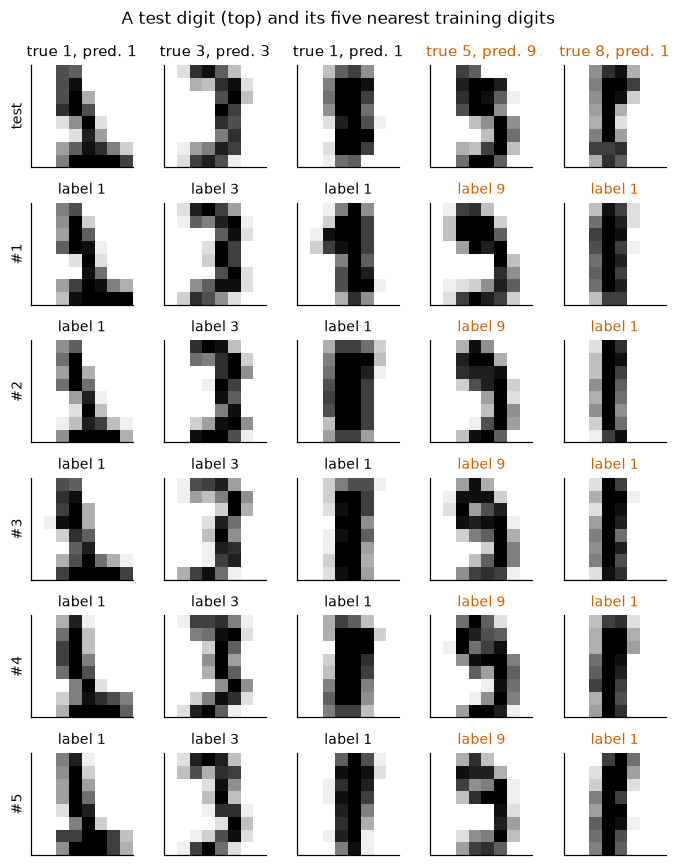

In [5]:
# Figure 4.1 — the five nearest neighbors of some test digits
def figure_4_1():
    knn = KNeighborsClassifier(n_neighbors=5).fit(X_tr, y_tr)
    pred = knn.predict(X_te)
    wrong = np.flatnonzero(pred != y_te)
    right = np.flatnonzero(pred == y_te)
    chosen = list(right[:3]) + list(wrong[:2])

    fig, axes = plt.subplots(6, 5, figsize=(6.4, 8.0))
    for col, i in enumerate(chosen):
        neighbors = knn.kneighbors(X_te[i:i + 1], return_distance=False)[0]
        axes[0, col].imshow(X_te[i].reshape(8, 8), cmap="gray_r")
        color = "black" if pred[i] == y_te[i] else VERMILION
        axes[0, col].set_title(f"true {y_te[i]}, pred. {pred[i]}", fontsize=9.5, color=color)
        for row, j in enumerate(neighbors, start=1):
            axes[row, col].imshow(X_tr[j].reshape(8, 8), cmap="gray_r")
            axes[row, col].set_title(f"label {y_tr[j]}", fontsize=9, color=("black" if y_tr[j] == y_te[i] else VERMILION))
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    axes[0, 0].set_ylabel("test", fontsize=9)
    for row in range(1, 6):
        axes[row, 0].set_ylabel(f"#{row}", fontsize=9)
    fig.suptitle("A test digit (top) and its five nearest training digits", fontsize=11)
    fig.tight_layout()
    plt.show()


figure_4_1()

In the three successful cases all five neighbors have the right label: the test digit sits in the middle of a cluster of similar images. In the two failures all five neighbors agree and are all wrong: the test digit (a $5$ drawn like a $9$, an $8$ drawn as a thin vertical stroke) is simply closer to the examples of another class than to the other examples of its own. This is the noise floor $R^\ast$ of Section 3.2 in action: no method that only sees these 64 numbers can do much better on such images.

### Worked example 4.1 — k-NN by hand

Six labeled points in the plane: class $\circ$ at $A = (0, 0)$, $B = (1, 0)$, $C = (0, 1)$ and class $\bullet$ at $D = (3, 3)$, $E = (4, 3)$, $F = (3, 4)$. Classify the new point $\mathbf{x} = (2, 2)$, and then the point $\mathbf{z} = (1, 1)$.

**By hand.** The squared distances from $\mathbf{x} = (2, 2)$ are $A$: $8$, $B$: $1 + 4 = 5$, $C$: $4 + 1 = 5$, $D$: $1 + 1 = 2$, $E$: $4 + 1 = 5$, $F$: $1 + 4 = 5$. The nearest neighbor is $D$ ($\bullet$), so $k = 1$ gives $\bullet$. For $k = 3$ the three nearest are $D$ and then *four points tied at squared distance 5* ($B$, $C$, $E$, $F$): the neighbor set is not uniquely defined, and the vote depends on how the tie is broken, from $\bullet\bullet\bullet$ to $\bullet\circ\circ$. This is not a pathological case: with integer-valued or rounded features exact ties are common, and the implementation of the tie-breaking rule can change the result. For $k = 5$ the neighbor set is $\{D, B, C, E, F\}$, with three $\bullet$ and two $\circ$, and the vote gives $\bullet$.

For $\mathbf{z} = (1, 1)$ the squared distances are $A$: $2$, $B$: $1$, $C$: $1$, $D$: $8$, $E$: $13$, $F$: $13$. The three nearest are $B$, $C$, $A$, all $\circ$, and $k = 1, 3$ give $\circ$. For $k = 5$ we add $D$ and one of $E$, $F$ (tied at 13): the vote is $3 \circ$ against $2 \bullet$, still $\circ$.

**With Python.** The cell below checks the distances and the votes. Note that `KNeighborsClassifier` returns a definite answer even for the tied case ($k = 3$ at $\mathbf{x}$, where it answers class 0, the two tied points that come first in the training set), but a different implementation could have answered differently.

In [6]:
P = np.array([[0, 0], [1, 0], [0, 1], [3, 3], [4, 3], [3, 4]], dtype=float)
labels = np.array([0, 0, 0, 1, 1, 1])                   # 0 = circle, 1 = bullet
for name, q in [("x = (2, 2)", [2.0, 2.0]), ("z = (1, 1)", [1.0, 1.0])]:
    d2 = ((P - np.array(q)) ** 2).sum(axis=1)
    print(f"{name}: squared distances to A..F = {d2}")
    for k in (1, 3, 5):
        pred = KNeighborsClassifier(n_neighbors=k).fit(P, labels).predict([q])[0]
        print(f"   k = {k}: predicted class {pred}")

x = (2, 2): squared distances to A..F = [8. 5. 5. 2. 5. 5.]
   k = 1: predicted class 1
   k = 3: predicted class 0
   k = 5: predicted class 1
z = (1, 1): squared distances to A..F = [ 2.  1.  1.  8. 13. 13.]
   k = 1: predicted class 0
   k = 3: predicted class 0
   k = 5: predicted class 0


## 4.3 How $k$ controls flexibility

### 4.3.1 The decision boundary

For a classifier the effect of $k$ is best seen in the plane. We take two features of the Wine data (`flavanoids` and `color_intensity`, which separate the three cultivars well but not perfectly), standardize them (Chapter 2: k-NN is distance-based, so the scales matter; the scaler is fitted on the training set only), and color the plane by the class that k-NN predicts at each point. Figure 4.2 shows four values of $k$.

training set of the figure, examples per cultivar: [41 50 33]


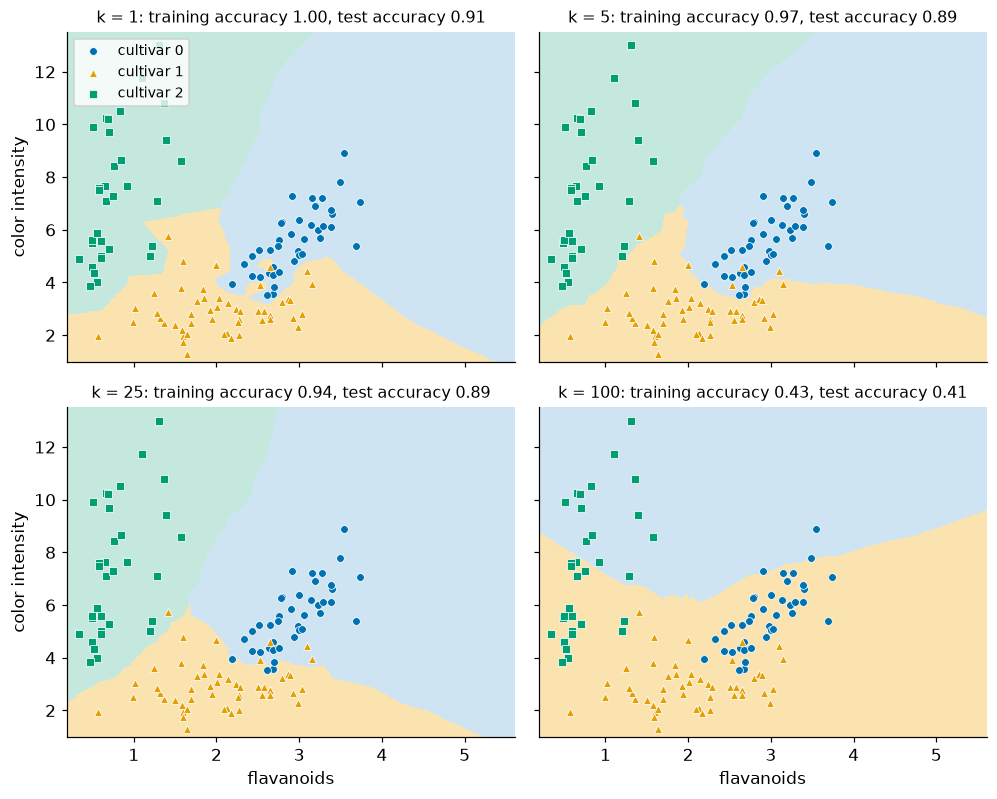

In [7]:
from sklearn.datasets import load_wine
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from matplotlib.colors import ListedColormap

wine = load_wine(as_frame=True)
features2 = ["flavanoids", "color_intensity"]
X_w2 = wine.data[features2].to_numpy()
y_w = wine.target.to_numpy()
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(X_w2, y_w, test_size=0.3, random_state=SEED, stratify=y_w)
print("training set of the figure, examples per cultivar:", np.bincount(yw_tr))


# Figure 4.2 — decision regions of k-NN for four values of k
def figure_4_2():
    ks = [1, 5, 25, 100]
    xx, yy = np.meshgrid(np.linspace(0.2, 5.6, 300), np.linspace(1.0, 13.5, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    light = ListedColormap(["#CFE4F3", "#FBE3B0", "#C4E8DD"])
    dark = [BLUE, ORANGE, GREEN]
    markers = ["o", "^", "s"]
    fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4), sharex=True, sharey=True)
    for ax, k in zip(axes.ravel(), ks):
        model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(Xw_tr, yw_tr)
        ax.pcolormesh(xx, yy, model.predict(grid).reshape(xx.shape), cmap=light, shading="auto", vmin=0, vmax=2)
        for c in range(3):
            ax.scatter(*Xw_tr[yw_tr == c].T, color=dark[c], marker=markers[c], s=26, edgecolor="white", linewidth=0.5,
                       label=f"cultivar {c}")
        ax.set_title(f"k = {k}: training accuracy {model.score(Xw_tr, yw_tr):.2f}, test accuracy {model.score(Xw_te, yw_te):.2f}", fontsize=10.5)
        ax.grid(False)
    for ax in axes[1]:
        ax.set_xlabel("flavanoids")
    for ax in axes[:, 0]:
        ax.set_ylabel("color intensity")
    axes[0, 0].legend(frameon=True, fontsize=9, loc="upper left")
    fig.tight_layout()
    plt.show()


figure_4_2()

**Reading the figure.** With $k = 1$ the plane is divided into the *Voronoi cells* of the training points: every training point owns the region closer to it than to any other point, so the boundary follows the training data exactly, with islands around isolated points (training accuracy 1.00, by construction). As $k$ grows the boundary smooths out, because a point must now beat several neighbors; at $k = 25$ the regions are three compact blobs. At $k = 100$ something drastic happens: the training set has only 124 points (41, 50 and 33 per cultivar), so a vote among 100 neighbors is almost a vote among *everybody*, cultivar 2 can never win it, and its region disappears; the test accuracy collapses to 0.41, close to the frequency of the largest class. The **number of neighbors is a smoothing parameter**: small $k$ means a complex, wiggly boundary (low bias, high variance in the language we are about to define), large $k$ a simple one (high bias, low variance).

### 4.3.2 The error curves, and why the training error cannot choose $k$

Figure 4.2 shows one split. To see the *typical* behavior we repeat the train/test split many times and average the accuracies, for every $k$ on a grid. We do it for two data sets of very different character: Digits (all 64 pixels) and the two-feature Wine problem above. In both we also compute the accuracy on the **training** set.

In [8]:
def accuracy_curves(X, y, ks, n_repeats=20, scale=False, test_size=0.3):
    """Mean and std of the training and test accuracy of k-NN over random stratified splits."""
    tr_acc = np.zeros((n_repeats, len(ks)))
    te_acc = np.zeros((n_repeats, len(ks)))
    for r in range(n_repeats):
        Xa, Xb, ya, yb = train_test_split(X, y, test_size=test_size, random_state=r, stratify=y)
        for j, k in enumerate(ks):
            model = KNeighborsClassifier(n_neighbors=k)
            if scale:
                model = make_pipeline(StandardScaler(), model)
            model.fit(Xa, ya)
            tr_acc[r, j], te_acc[r, j] = model.score(Xa, ya), model.score(Xb, yb)
    return tr_acc, te_acc


ks_digits = [1, 2, 3, 5, 7, 10, 15, 25, 50, 100, 200]
ks_wine = [1, 2, 3, 5, 7, 10, 15, 20, 30, 40, 60, 80, 100]
curves = {
    "digits": (ks_digits, *accuracy_curves(X_dg, y_dg, ks_digits)),
    "wine2": (ks_wine, *accuracy_curves(X_w2, y_w, ks_wine, scale=True)),
}
for name, (ks, tr_acc, te_acc) in curves.items():
    table = pd.DataFrame({"training": tr_acc.mean(axis=0), "test": te_acc.mean(axis=0), "std of test": te_acc.std(axis=0)}, index=pd.Index(ks, name="k"))
    print(f"--- {name}: mean accuracy over 20 random 70/30 splits")
    print(table.round(4).T.to_string())
    best = ks[int(te_acc.mean(axis=0).argmax())]
    print(f"best k on the test sets = {best} (test accuracy {te_acc.mean(axis=0).max():.4f}); "
          f"k chosen by the training accuracy = {ks[int(tr_acc.mean(axis=0).argmax())]}\n")

--- digits: mean accuracy over 20 random 70/30 splits
k               1       2       3       5       7       10      15      25      50      100     200
training     1.0000  0.9912  0.9930  0.9905  0.9891  0.9855  0.9803  0.9681  0.9447  0.9136  0.8789
test         0.9850  0.9823  0.9839  0.9833  0.9809  0.9777  0.9725  0.9635  0.9419  0.9133  0.8798
std of test  0.0047  0.0048  0.0047  0.0040  0.0037  0.0055  0.0061  0.0075  0.0102  0.0113  0.0143
best k on the test sets = 1 (test accuracy 0.9850); k chosen by the training accuracy = 1

--- wine2: mean accuracy over 20 random 70/30 splits
k               1       2       3       5       7       10      15      20      30      40      60      80      100
training     1.0000  0.9504  0.9528  0.9484  0.9347  0.9391  0.9391  0.9294  0.9044  0.8911  0.8282  0.7073  0.4339
test         0.9194  0.9111  0.9259  0.9204  0.9176  0.9241  0.9296  0.9176  0.8972  0.8796  0.8296  0.7019  0.4148
std of test  0.0264  0.0296  0.0293  0.0275  0.0207  0

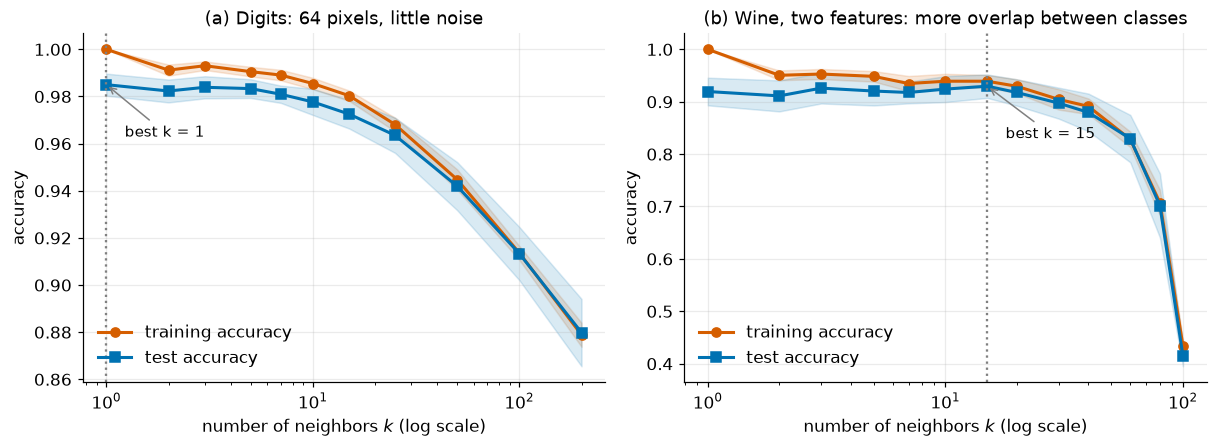

In [9]:
# Figure 4.3 — training and test accuracy of k-NN as a function of k
def figure_4_3():
    titles = {"digits": "(a) Digits: 64 pixels, little noise", "wine2": "(b) Wine, two features: more overlap between classes"}
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
    for ax, (name, (ks, tr_acc, te_acc)) in zip(axes, curves.items()):
        for acc, color, marker, label in [(tr_acc, VERMILION, "o", "training accuracy"), (te_acc, BLUE, "s", "test accuracy")]:
            ax.plot(ks, acc.mean(axis=0), color=color, marker=marker, linewidth=2, label=label)
            ax.fill_between(ks, acc.mean(axis=0) - acc.std(axis=0), acc.mean(axis=0) + acc.std(axis=0), color=color, alpha=0.15)
        best = int(te_acc.mean(axis=0).argmax())
        ax.axvline(ks[best], color="gray", linestyle=":", linewidth=1.5)
        ax.annotate(f"best k = {ks[best]}", (ks[best], te_acc.mean(axis=0)[best]), xytext=(12, -34), textcoords="offset points",
                    fontsize=10, arrowprops=dict(arrowstyle="->", color="gray"))
        ax.set_xscale("log")
        ax.set(xlabel="number of neighbors $k$ (log scale)", ylabel="accuracy", title=titles[name])
        ax.legend(frameon=False, loc="lower left")
    fig.tight_layout()
    plt.show()


figure_4_3()

**What the curves say.**

1. **The training accuracy cannot choose $k$.** It equals exactly 1.00 at $k = 1$ in both panels and falls as $k$ grows, so the rule "pick the $k$ with the best training accuracy" returns $k = 1$ on every problem (last line of each block of output). This is the optimism of Section 3.4 in its purest form: a 1-NN classifier memorizes the training set, and a method that memorizes is not tested by the training data. On Wine the gap between the two curves at $k = 1$ is $1.000 - 0.919 = 0.081$; at $k = 15$ it is $0.939 - 0.930$, about 0.01. The test set, or the validation procedures of Chapter 5, are what we use to choose.
2. **The best $k$ depends on how noisy the problem is.** On Digits the best $k$ is 1 (0.985), and $k$ up to 5 is statistically indistinguishable from it: the classes are almost separable in pixel space, so the single nearest neighbor is nearly always right and averaging several neighbors only adds a bias. On the two Wine features the classes overlap, a single neighbor is unreliable, and the test accuracy peaks at $k = 15$ (0.930), although everything from $k = 1$ to $k = 20$ lies within one standard deviation of it. The numbers of this experiment cannot resolve a finer choice; the message is that *there is a wide plateau, and that the plateau is wider and shifts to larger $k$ when the data are noisier*.
3. **Too large a $k$ underfits.** Past the plateau both curves fall together (the gap between training and test accuracy vanishes, because the model has become too simple to depend on the particular sample): Digits drops to 0.880 at $k = 200$, Wine to 0.415 at $k = 100$, where the vote reports little more than the class frequencies.

Chapter 3 described this picture in general terms (Figure 3.3): a flexible model has a large estimation error, a rigid one a large approximation error. The next sections make it precise for the squared loss, where the trade-off becomes an exact formula.

## 4.4 k-NN for regression

For a numeric target the prediction is the **average** of the targets of the $k$ nearest neighbors, $\hat f_k(\mathbf{x}) = \frac{1}{k}\sum_{i\in N_k(\mathbf{x})} y_i$. It is a *local average*, the simplest example of a **nonparametric** estimator of the regression function $\eta(\mathbf{x}) = \mathbb{E}[y\mid\mathbf{x}]$ of Section 3.2: it makes no assumption about the shape of $\eta$ beyond "similar inputs have similar targets". The result is a piecewise-constant function, which jumps whenever the set of neighbors changes.

We use the **Diabetes** data (442 patients, ten baseline measurements, and a numeric measure of disease progression one year later, which we will call the *progression*). Starting with one feature makes the fitted function visible: Figure 4.4 shows the progression against the body-mass index (`bmi`), with the k-NN fit for four values of $k$ and, for comparison, the least-squares line.

patients: 442 | features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
each feature is already centered, with the same scale: column std [0.048 0.048 0.048] ...


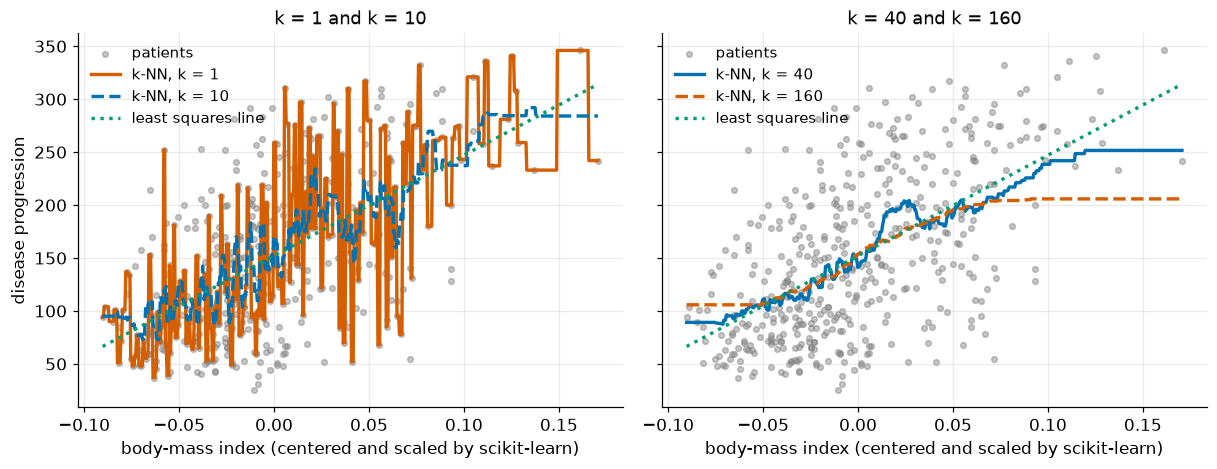

In [10]:
from sklearn.datasets import load_diabetes
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression

diabetes = load_diabetes(as_frame=True)
X_db = diabetes.data.to_numpy()
y_db = diabetes.target.to_numpy()
feature_names = list(diabetes.data.columns)
bmi = X_db[:, [feature_names.index("bmi")]]
print("patients:", len(y_db), "| features:", feature_names)
print("each feature is already centered, with the same scale: column std", X_db.std(axis=0).round(3)[:3], "...")


# Figure 4.4 — k-NN regression of the progression on bmi, for four values of k
def figure_4_4():
    grid = np.linspace(bmi.min(), bmi.max(), 600)[:, None]
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.4), sharey=True)
    for ax, ks, colors in [(axes[0], [1, 10], [VERMILION, BLUE]), (axes[1], [40, 160], [BLUE, VERMILION])]:
        ax.scatter(bmi, y_db, s=14, color="gray", alpha=0.45, label="patients")
        for k, color, ls in zip(ks, colors, ["-", "--"]):
            ax.plot(grid, KNeighborsRegressor(n_neighbors=k).fit(bmi, y_db).predict(grid), color=color, linestyle=ls, linewidth=2.2, label=f"k-NN, k = {k}")
        ax.plot(grid, LinearRegression().fit(bmi, y_db).predict(grid), color=GREEN, linestyle=":", linewidth=2.2, label="least squares line")
        ax.set(xlabel="body-mass index (centered and scaled by scikit-learn)", title=f"k = {ks[0]} and k = {ks[1]}")
        ax.legend(frameon=False, loc="upper left", fontsize=9.5)
    axes[0].set_ylabel("disease progression")
    fig.tight_layout()
    plt.show()


figure_4_4()

The same picture as in the classification case: $k = 1$ passes through every point and jumps wildly (it fits the noise); $k = 10$ is still rough; $k = 40$ follows a smooth, nearly linear trend that bends slightly at the extremes; $k = 160$, a vote among more than a third of the patients, flattens the curve and loses the trend at both ends (a *bias* toward the global mean). Note also that at the edges of the $x$-range all neighbors lie on one side of the query point, which pulls the average toward the interior: the **boundary effect**, which will matter in the next section.

How accurate are these fits? We measure the **mean squared error** (MSE) on held-out patients, averaged over 20 random 70/30 splits, for $k$ from 1 to 160, using the single feature `bmi` and then all ten features, and compare with linear regression on the same inputs. (Chapter 5 will present better ways to do this; here repeated splits are enough.)

In [11]:
def regression_mse(features, ks, n_repeats=20):
    """Mean test MSE of k-NN regression for each k, and of least squares, over random 70/30 splits."""
    mse_knn = np.zeros((n_repeats, len(ks)))
    mse_lin = np.zeros(n_repeats)
    for r in range(n_repeats):
        Xa, Xb, ya, yb = train_test_split(X_db[:, features], y_db, test_size=0.3, random_state=r)
        for j, k in enumerate(ks):
            mse_knn[r, j] = np.mean((KNeighborsRegressor(n_neighbors=k).fit(Xa, ya).predict(Xb) - yb) ** 2)
        mse_lin[r] = np.mean((LinearRegression().fit(Xa, ya).predict(Xb) - yb) ** 2)
    return mse_knn.mean(axis=0), mse_lin.mean()


ks_reg = [1, 5, 10, 20, 40, 80, 160]
rows = {}
for name, cols in [("bmi only", [feature_names.index("bmi")]), ("all 10 features", list(range(10)))]:
    mse_knn, mse_lin = regression_mse(cols, ks_reg)
    rows[name] = {**{f"k = {k}": v for k, v in zip(ks_reg, mse_knn)}, "least squares": mse_lin}
print(f"variance of the target (the MSE of always predicting the mean): {y_db.var():.0f}\n")
print(pd.DataFrame(rows).T.round(0).astype(int).to_string())

variance of the target (the MSE of always predicting the mean): 5930

                 k = 1  k = 5  k = 10  k = 20  k = 40  k = 80  k = 160  least squares
bmi only          7419   4508    4162    4033    3965    4003     4262           3801
all 10 features   6208   3682    3365    3283    3371    3531     4089           3016


Three lessons. First, the same U-shape of Chapter 1 appears: with `bmi` alone the error falls from 7,621 at $k = 1$ to a minimum near $k = 40$ and rises again at $k = 160$, and for all ten features the best value is $k = 20$. Second, $k = 1$ is much *worse* than predicting the mean (variance of the target 5,930), the most visible symptom of fitting the noise. Third, and this is important to say, **k-NN does not win here**: least squares is better than the best k-NN, in both settings. The reason is again the inductive bias of Section 3.9. The relation between these ten measurements and the progression is close to linear, and a model that *assumes* linearity uses all 309 training patients to estimate a handful of coefficients, while k-NN, which assumes only smoothness, averages over a few dozen neighbors in a ten-dimensional space where neighbors are not very close (Section 4.7). A more flexible method is better only when the truth requires the flexibility, or when there is enough data to pay for it.

## 4.5 The bias–variance decomposition

### 4.5.1 The squared error at a point, split in three

Consider a fixed input $\mathbf{x}_0$. The target there is $y_0 = f(\mathbf{x}_0) + \varepsilon$, where $f(\mathbf{x}_0) = \mathbb{E}[y_0\mid\mathbf{x}_0]$ is the regression function $\eta$ of Chapter 3 (we write $f$ for the *true* function from now on) and the noise $\varepsilon$ has mean 0 and variance $\sigma^2$, independent of everything else. We train a method on a **random** training set $S$ and get the prediction $\hat f_S(\mathbf{x}_0)$, which is itself a random variable because $S$ is random. The expected squared error at $\mathbf{x}_0$, averaged over the noise of the new target **and over the training set**, splits into three non-negative pieces:

$$
\boxed{\;\mathbb{E}\Big[\big(y_0 - \hat f_S(\mathbf{x}_0)\big)^2\Big]
= \underbrace{\sigma^2}_{\text{noise}}
+ \underbrace{\big(f(\mathbf{x}_0) - \mathbb{E}[\hat f_S(\mathbf{x}_0)]\big)^2}_{\text{bias}^2}
+ \underbrace{\mathbb{E}\Big[\big(\hat f_S(\mathbf{x}_0) - \mathbb{E}[\hat f_S(\mathbf{x}_0)]\big)^2\Big]}_{\text{variance}}\;}
$$

:::{admonition} Proof
:class: dropdown
Write $\bar f = \mathbb{E}[\hat f_S(\mathbf{x}_0)]$ for the average prediction over training sets, and add and subtract $f(\mathbf{x}_0)$ and $\bar f$:
$$
y_0 - \hat f_S = \underbrace{(y_0 - f)}_{\varepsilon} + \underbrace{(f - \bar f)}_{\text{a constant}} + \underbrace{(\bar f - \hat f_S)}_{\text{mean zero}} .
$$
Square the sum. The three squares give $\sigma^2$, $(f - \bar f)^2$ and $\operatorname{Var}(\hat f_S)$. The cross terms vanish: $\mathbb{E}[\varepsilon\,(f - \bar f)] = 0$ because $\varepsilon$ has mean 0 and $f - \bar f$ is a constant; $\mathbb{E}[\varepsilon\,(\bar f - \hat f_S)] = 0$ because $\varepsilon$ (the noise in the *new* target) is independent of the training set; and $\mathbb{E}[(f - \bar f)(\bar f - \hat f_S)] = (f - \bar f)\,\mathbb{E}[\bar f - \hat f_S] = 0$. $\square$
:::

- The **noise** $\sigma^2$ is the part of the target that no function of $\mathbf{x}$ can predict: it is the Bayes risk $R^\ast$ of Section 3.2 (for the squared loss, the conditional variance, here constant). It does not depend on the method.
- The **bias** measures a *systematic* error: how far the average prediction, over many hypothetical training sets, is from the truth. A method with a high bias is too rigid to represent $f$.
- The **variance** measures *sensitivity to the sample*: how much the prediction at $\mathbf{x}_0$ would change if we drew another training set of the same size. A method with a high variance reacts to the idiosyncrasies of the sample, i.e. to its noise.

Averaging over $\mathbf{x}_0$ gives the expected risk of Chapter 3: $\mathbb{E}_S[R(\hat f_S)] = R^\ast + \overline{\text{bias}^2} + \overline{\text{variance}}$. This is a close cousin of the split of Section 3.3 into approximation and estimation error, and it is easy to confuse the two. In Chapter 3 the approximation error was a property of the *class* $\mathcal{H}$ (the distance between its best member and the truth), and the estimation error the extra price for choosing a member from a finite sample. Here bias and variance are properties of the *algorithm* at a given sample size; bias is the average distance to the truth of the function the algorithm returns (which includes the approximation error, and also the systematic effect of how it chooses within the class), and variance is the randomness of that function. For a rich class and plenty of data they are nearly the same thing, and in both pictures the message is the same: *flexibility reduces bias and increases variance*.

:::{admonition} Pitfall — the decomposition is for the squared loss
:class: warning
The three terms add up *exactly* only for the squared loss. For the 0–1 loss of classification the error does not split additively, and several different "bias–variance decompositions" have been proposed, none with all the nice properties. The qualitative picture (a flexible classifier has a high variance, a rigid one a high bias) remains true, and Figures 4.2 and 4.3 are its illustration.
:::

### 4.5.2 The decomposition of k-NN regression, in closed form

For k-NN regression the three terms can be computed explicitly if we make the simplest assumption on how the training inputs are generated: the **fixed design**, in which the inputs $\mathbf{x}_1, \dots, \mathbf{x}_n$ are fixed numbers and only the targets $y_i = f(\mathbf{x}_i) + \varepsilon_i$ are random, with independent noises of variance $\sigma^2$. (This is the standard setting of the theory of regression, and it makes the neighbor set $N_k(\mathbf{x}_0)$ non-random, which is what makes an exact computation possible.) The prediction is $\hat f_k(\mathbf{x}_0) = \frac1k\sum_{i\in N_k(\mathbf{x}_0)}\big(f(\mathbf{x}_i) + \varepsilon_i\big)$, and therefore

$$
\mathbb{E}\big[\hat f_k(\mathbf{x}_0)\big] = \frac1k\sum_{i\in N_k(\mathbf{x}_0)} f(\mathbf{x}_i),
\qquad
\operatorname{Var}\big[\hat f_k(\mathbf{x}_0)\big] = \frac{1}{k^2}\sum_{i\in N_k(\mathbf{x}_0)}\sigma^2 = \frac{\sigma^2}{k}.
$$

(The variance of a sum of independent variables is the sum of the variances; the factor $1/k^2$ comes from the average.) The expected squared error at $\mathbf{x}_0$ is thus

$$
\boxed{\;\mathbb{E}\Big[\big(y_0 - \hat f_k(\mathbf{x}_0)\big)^2\Big] = \sigma^2 + \Big(f(\mathbf{x}_0) - \frac1k\sum_{i\in N_k(\mathbf{x}_0)} f(\mathbf{x}_i)\Big)^2 + \frac{\sigma^2}{k}\;}
$$

Everything is now visible. The **variance is $\sigma^2/k$**: it decreases like $1/k$, because we average more noisy numbers, and for $k = 1$ it equals the noise itself, so that **1-NN doubles the unavoidable error** ($\sigma^2 + \sigma^2$, if the bias is negligible). The **bias** is the difference between the true value at $\mathbf{x}_0$ and the average of the true values at the neighbors; it grows with $k$ because the neighbors that are added are farther away, where $f$ differs more from $f(\mathbf{x}_0)$.

### Worked example 4.2 — bias and variance by hand

Let $f(x) = x^2$ and $\sigma^2 = 0.25$, with the training inputs $x = 0, 1, 2, 3, 4$ (so that $f = 0, 1, 4, 9, 16$). Take $x_0 = 2$ (a point of the design, in the interior).

**By hand.** For $k = 1$: $N_1 = \{2\}$, the average of $f$ over the neighbors is $4 = f(x_0)$, so the bias is 0 and the variance is $0.25$; total $0.25 + 0 + 0.25 = 0.50$. For $k = 3$: $N_3 = \{1, 2, 3\}$, average $(1 + 4 + 9)/3 = 14/3 = 4.667$, bias $= 4 - 4.667 = -0.667$, bias$^2 = 0.444$ (it is the convexity of $f$ that causes it, the neighbors on both sides lie *above* the value at the center), variance $0.25/3 = 0.0833$; total $0.25 + 0.444 + 0.083 = 0.778$. For $k = 5$: all points, average $(0 + 1 + 4 + 9 + 16)/5 = 6$, bias$^2 = 4$, variance $0.05$, total $4.30$. The best $k$ at this point is the *smallest*: the noise is small relative to the curvature of $f$.

**With Python.** The check below also simulates the whole process: it generates 100,000 training sets (new noise each time), predicts at $x_0 = 2$ and measures the squared error against a fresh noisy target.

In [12]:
x_design = np.arange(5.0)
f_true = lambda x: x ** 2
sigma2, x0 = 0.25, 2.0
rng = np.random.default_rng(SEED)
reps = 100_000
noise = rng.normal(0, np.sqrt(sigma2), size=(reps, 5))
y_new = f_true(x0) + rng.normal(0, np.sqrt(sigma2), size=reps)
order = np.argsort(np.abs(x_design - x0), kind="stable")

rows = []
for k in (1, 3, 5):
    nn = order[:k]
    bias = f_true(x0) - f_true(x_design[nn]).mean()
    pred = (f_true(x_design)[None, :] + noise)[:, nn].mean(axis=1)
    rows.append({"k": k, "bias^2 (formula)": bias ** 2, "variance (formula)": sigma2 / k,
                 "total (formula)": sigma2 + bias ** 2 + sigma2 / k, "simulated mean squared error": np.mean((y_new - pred) ** 2)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

 k  bias^2 (formula)  variance (formula)  total (formula)  simulated mean squared error
 1            0.0000              0.2500           0.5000                        0.5002
 3            0.4444              0.0833           0.7778                        0.7808
 5            4.0000              0.0500           4.3000                        4.3082


The simulation agrees with the formula to within about 0.2%.

### 4.5.3 Checking the formulas on a whole function

Now we let $\mathbf{x}_0$ vary. We use the **simulated** world $f(x) = \sin(2\pi x)$ on $[0, 1]$, noise $\sigma = 0.3$ (so $\sigma^2 = 0.09$), and $n = 100$ equally spaced training inputs $x_i = (i - \tfrac12)/n$. Because the formula of Section 4.5.2 is exact, we can compute the bias and the variance at every $x_0$ in closed form, average them over $x_0 \in [0, 1]$, and then *confirm them by brute force*, generating thousands of training sets. Figure 4.5 shows the fits obtained from 30 different training sets for three values of $k$.

In [13]:
def f_sin(x):
    return np.sin(2 * np.pi * x)


N_DESIGN, SIGMA = 100, 0.3
x_design = (np.arange(N_DESIGN) + 0.5) / N_DESIGN                   # fixed design: equally spaced inputs
x_grid = np.linspace(0, 1, 401)                                      # the points x0 where we evaluate the fit


def neighbor_indices(x_train, x_query, k):
    """Indices of the k nearest training inputs of each query point (1-D inputs, ties broken by position)."""
    dist = np.abs(x_train[None, :] - x_query[:, None])
    return np.argsort(dist, axis=1, kind="stable")[:, :k]


def exact_decomposition(k, n=N_DESIGN, sigma=SIGMA, x_query=x_grid):
    """Average over x0 of the bias^2 and of the variance of k-NN regression with a fixed design (formulas of Section 4.5.2)."""
    x_train = (np.arange(n) + 0.5) / n
    nn = neighbor_indices(x_train, x_query, k)
    bias2 = (f_sin(x_query) - f_sin(x_train)[nn].mean(axis=1)) ** 2
    return bias2.mean(), sigma ** 2 / k


rng = np.random.default_rng(SEED)
n_sets = 3000
y_sets = f_sin(x_design)[None, :] + rng.normal(0, SIGMA, size=(n_sets, N_DESIGN))      # 3000 training sets (only the targets change)
fits = {k: y_sets[:, neighbor_indices(x_design, x_grid, k)].mean(axis=2) for k in (1, 3, 5, 8, 12, 20, 30, 50)}   # (3000, 401) fits for each k

rows = []
for k, pred in fits.items():
    b2_exact, var_exact = exact_decomposition(k)
    y_fresh = f_sin(x_grid)[None, :] + rng.normal(0, SIGMA, size=pred.shape)
    rows.append({"k": k, "bias^2 exact": b2_exact, "bias^2 simulated": np.mean((pred.mean(axis=0) - f_sin(x_grid)) ** 2),
                 "variance exact": var_exact, "variance simulated": pred.var(axis=0).mean(),
                 "test MSE exact": SIGMA ** 2 + b2_exact + var_exact, "test MSE simulated": np.mean((y_fresh - pred) ** 2)})
check = pd.DataFrame(rows)
print(check.round(4).to_string(index=False))

 k  bias^2 exact  bias^2 simulated  variance exact  variance simulated  test MSE exact  test MSE simulated
 1        0.0002            0.0002          0.0900              0.0901          0.1802              0.1803
 3        0.0003            0.0003          0.0300              0.0300          0.1203              0.1203
 5        0.0006            0.0006          0.0180              0.0180          0.1086              0.1086
 8        0.0019            0.0020          0.0112              0.0113          0.1032              0.1030
12        0.0057            0.0057          0.0075              0.0075          0.1032              0.1033
20        0.0207            0.0208          0.0045              0.0044          0.1152              0.1150
30        0.0465            0.0466          0.0030              0.0030          0.1395              0.1396
50        0.0812            0.0812          0.0018              0.0018          0.1730              0.1727


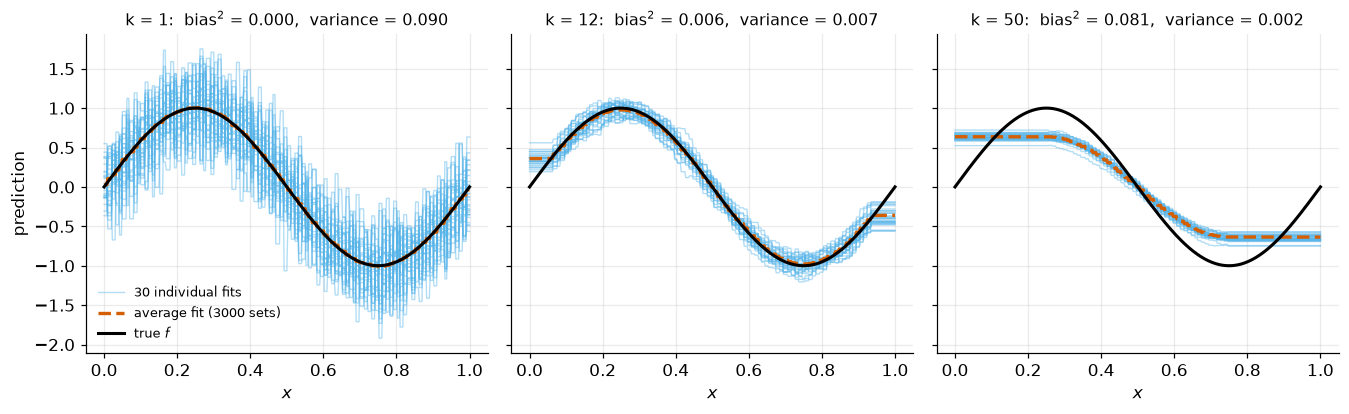

In [14]:
# Figure 4.5 — thirty fits of k-NN regression, from thirty different training sets
def figure_4_5():
    fig, axes = plt.subplots(1, 3, figsize=(12.4, 3.9), sharey=True)
    for ax, k in zip(axes, [1, 12, 50]):
        for r in range(30):
            ax.plot(x_grid, fits[k][r], color=SKY, alpha=0.45, linewidth=0.9, label="30 individual fits" if r == 0 else None)
        ax.plot(x_grid, fits[k].mean(axis=0), color=VERMILION, linewidth=2.2, linestyle="--", label="average fit (3000 sets)")
        ax.plot(x_grid, f_sin(x_grid), color="black", linewidth=2, label="true $f$")
        b2, var = exact_decomposition(k)
        ax.set_title(f"k = {k}:  bias$^2$ = {b2:.3f},  variance = {var:.3f}", fontsize=10.5)
        ax.set_xlabel("$x$")
    axes[0].set_ylabel("prediction")
    axes[0].legend(frameon=False, fontsize=8.5, loc="lower left")
    fig.tight_layout()
    plt.show()


figure_4_5()

In the left panel ($k = 1$) every fit is a noisy staircase: the thirty curves scatter widely around the truth, but their average (dashed) lies on top of it. **The bias is nearly zero and the variance is large**: $0.090 = \sigma^2$, as predicted. In the right panel ($k = 50$) the fits are almost identical to one another (variance $0.002$) but all of them are wrong in the same way, flattening the peaks of the sine: **the bias is large and the variance small**. The middle panel ($k = 12$) is a good compromise. Note also, at the ends of the interval, where all neighbors lie on one side of $x_0$, the average fit sits below the peak of the curve even for $k = 12$: this is the boundary effect that we saw in Figure 4.4.

The table printed before the figure compares, for eight values of $k$, the exact formulas with a brute-force simulation of 3,000 training sets. The agreement is to three or four decimals for every entry: the decomposition is not a heuristic but an identity.

Because the formulas are exact, we can compute the whole curve for every $k$ from 1 to 100 and find the best one, without any simulation. Figure 4.6 is the central picture of this chapter.

In [15]:
ks_all = np.arange(1, 101)
decomp = pd.DataFrame([(k, *exact_decomposition(k)) for k in ks_all], columns=["k", "bias2", "variance"]).set_index("k")
decomp["expected test MSE"] = SIGMA ** 2 + decomp["bias2"] + decomp["variance"]
k_best = int(decomp["expected test MSE"].idxmin())
print(f"noise sigma^2 = {SIGMA ** 2:.4f}")
print(f"best k = {k_best}: bias^2 = {decomp.loc[k_best, 'bias2']:.4f}, variance = {decomp.loc[k_best, 'variance']:.4f}, "
      f"expected test MSE = {decomp.loc[k_best, 'expected test MSE']:.4f}")
print(f"k = 1 : expected test MSE = {decomp.loc[1, 'expected test MSE']:.4f}  (twice the noise level: {2 * SIGMA ** 2:.4f})")
print(f"k = 100: expected test MSE = {decomp.loc[100, 'expected test MSE']:.4f}  (it predicts the mean of f, which is 0)")
print("k where the bias^2 equals the variance:", int((decomp['bias2'] - decomp['variance']).abs().idxmin()))

noise sigma^2 = 0.0900
best k = 10: bias^2 = 0.0035, variance = 0.0090, expected test MSE = 0.1025
k = 1 : expected test MSE = 0.1802  (twice the noise level: 0.1800)
k = 100: expected test MSE = 0.5897  (it predicts the mean of f, which is 0)
k where the bias^2 equals the variance: 13


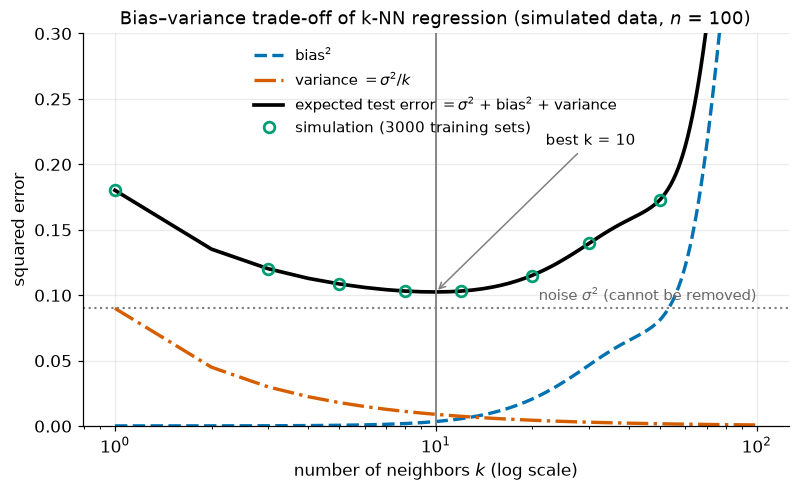

In [16]:
# Figure 4.6 — bias, variance and expected test error of k-NN regression as a function of k
def figure_4_6():
    fig, ax = plt.subplots(figsize=(7.4, 4.6))
    ax.plot(decomp.index, decomp["bias2"], color=BLUE, linewidth=2.2, linestyle="--", label="bias$^2$")
    ax.plot(decomp.index, decomp["variance"], color=VERMILION, linewidth=2.2, linestyle="-.", label="variance $=\\sigma^2/k$")
    ax.axhline(SIGMA ** 2, color="gray", linewidth=1.4, linestyle=":")
    ax.text(100, SIGMA ** 2 + 0.006, "noise $\\sigma^2$ (cannot be removed)", ha="right", fontsize=9.5, color="dimgray")
    ax.plot(decomp.index, decomp["expected test MSE"], color="black", linewidth=2.4, label="expected test error $=\\sigma^2$ + bias$^2$ + variance")
    ax.plot(check["k"], check["test MSE simulated"], linestyle="none", marker="o", markersize=7, markerfacecolor="none",
            markeredgecolor=GREEN, markeredgewidth=1.8, label="simulation (3000 training sets)")
    ax.axvline(k_best, color="gray", linewidth=1.2)
    ax.annotate(f"best k = {k_best}", (k_best, decomp.loc[k_best, "expected test MSE"]), xytext=(22, 0.215), fontsize=10,
                arrowprops=dict(arrowstyle="->", color="gray"))
    ax.set_xscale("log"); ax.set_ylim(0, 0.3)
    ax.set(xlabel="number of neighbors $k$ (log scale)", ylabel="squared error", title="Bias–variance trade-off of k-NN regression (simulated data, $n$ = 100)")
    ax.legend(frameon=False, fontsize=9.5, loc="upper center")
    fig.tight_layout()
    plt.show()


figure_4_6()

**Reading the figure.** The variance (dash-dot) falls like $1/k$ and the bias$^2$ (dashed) rises with $k$: it is negligible while the neighborhood is narrow compared with the wavelength of the sine, and grows fast once the neighborhood spans a good part of a period. Their sum plus the noise (black) is U-shaped, with a minimum at $k = 10$, where the expected test error is 0.1025, only 0.0125 above the noise floor $\sigma^2 = 0.09$. The two extremes are bad for opposite reasons: $k = 1$ costs twice the noise, because the variance equals $\sigma^2$, and $k = 100$ (the global mean) gives an expected error of 0.59, almost six times that of the best $k$, because the bias is almost the whole variance of the signal. This U-shape is the model-complexity curve that has appeared in every chapter so far (Figures 1.4 and 3.3), now with an exact formula behind it. A very useful rule of thumb is visible: **at the best $k$ the bias$^2$ (0.0035) and the variance (0.0090) are of the same order** (they are equal at $k = 13$, a little to the right of the minimum, because the bias grows faster than the variance falls); a method whose variance is far larger than its squared bias is too flexible, and the opposite means it is too rigid.

### 4.5.4 The best $k$ grows with $n$, while the neighborhoods shrink

How does the best $k$ change when we have more data? Take the same sine and the same $\sigma$, with $n = 25, 50, \dots, 12{,}800$ equally spaced inputs, compute the exact curves, and find for each $n$ the $k$ that minimizes the expected error and the error it achieves (we report the *excess* error over the noise floor, $\text{bias}^2 + \sigma^2/k$, which is what the method is responsible for).

In [17]:
def excess_curve(n, x_query):
    """Exact excess risk bias^2 + sigma^2/k of fixed-design k-NN regression, for every k = 1..n, averaged over x_query."""
    x_train = (np.arange(n) + 0.5) / n
    order = np.argsort(np.abs(x_train[None, :] - x_query[:, None]), axis=1, kind="stable")
    k = np.arange(1, n + 1)
    mean_of_f = np.cumsum(f_sin(x_train)[order], axis=1) / k[None, :]          # average of f over the k nearest, for every k at once
    return ((f_sin(x_query)[:, None] - mean_of_f) ** 2).mean(axis=0) + SIGMA ** 2 / k


ns = np.array([25, 50, 100, 200, 400, 800, 1600, 3200, 6400, 12800])
region_grids = {"whole interval [0, 1]": np.linspace(0, 1, 401), "interior [0.2, 0.8]": np.linspace(0.2, 0.8, 241)}
best = {}
for name, grid in region_grids.items():
    ks_best, risks = [], []
    for n in ns:
        curve = excess_curve(n, grid)
        ks_best.append(int(curve.argmin()) + 1); risks.append(curve.min())
    best[name] = (np.array(ks_best), np.array(risks))
    slope_k = np.polyfit(np.log(ns), np.log(ks_best), 1)[0]
    slope_r = np.polyfit(np.log(ns), np.log(risks), 1)[0]
    print(f"{name}: slope of log k* against log n = {slope_k:.2f} | slope of log(excess error) against log n = {slope_r:.2f}")

summary = pd.DataFrame({"n": ns, "best k (whole interval)": best["whole interval [0, 1]"][0], "k/n": best["whole interval [0, 1]"][0] / ns,
                        "excess error": best["whole interval [0, 1]"][1]})
print(summary.round(4).to_string(index=False))

whole interval [0, 1]: slope of log k* against log n = 0.73 | slope of log(excess error) against log n = -0.74
interior [0.2, 0.8]: slope of log k* against log n = 0.79 | slope of log(excess error) against log n = -0.81
    n  best k (whole interval)    k/n  excess error
   25                        4 0.1600        0.0362
   50                        6 0.1200        0.0211
  100                       10 0.1000        0.0125
  200                       16 0.0800        0.0075
  400                       28 0.0700        0.0044
  800                       46 0.0575        0.0027
 1600                       76 0.0475        0.0016
 3200                      128 0.0400        0.0010
 6400                      214 0.0334        0.0006
12800                      356 0.0278        0.0003


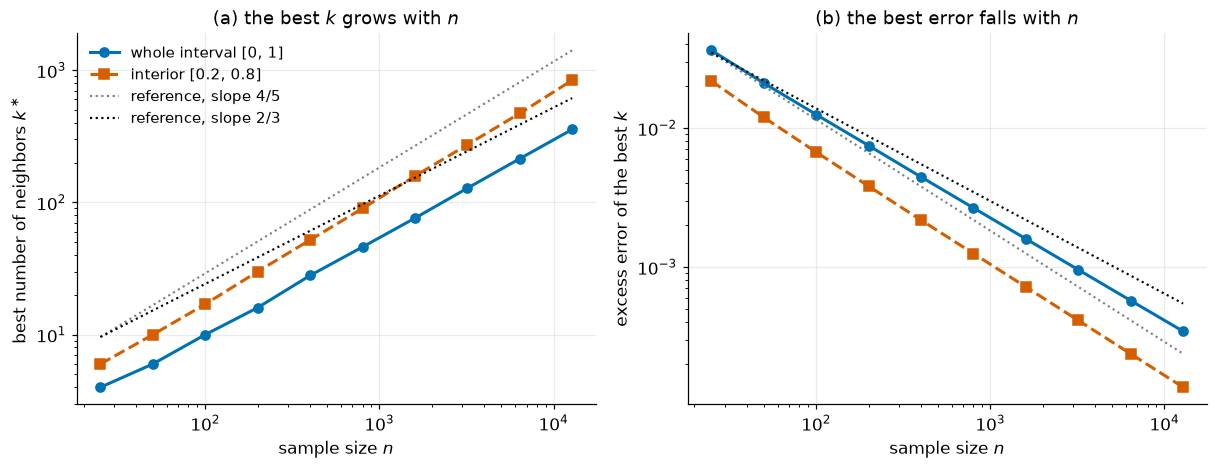

In [18]:
# Figure 4.7 — the best k and the best excess error as functions of the sample size
def figure_4_7():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.4))
    styles = {"whole interval [0, 1]": (BLUE, "o", "-"), "interior [0.2, 0.8]": (VERMILION, "s", "--")}
    for ax, idx, ylabel in [(axes[0], 0, "best number of neighbors $k^\\ast$"), (axes[1], 1, "excess error of the best $k$")]:
        for name, (color, marker, ls) in styles.items():
            ax.plot(ns, best[name][idx], color=color, marker=marker, linestyle=ls, linewidth=2, label=name)
        for slope, color, label in [(4 / 5, "gray", "slope 4/5"), (2 / 3, "black", "slope 2/3")]:
            sign = 1 if idx == 0 else -1
            ref = best["interior [0.2, 0.8]"][idx][0] * (ns / ns[0]) ** (sign * slope)
            ax.plot(ns, ref * (1.6 if idx == 0 else 1.6), color=color, linestyle=":", linewidth=1.4, label=f"reference, {label}" if idx == 0 else None)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set(xlabel="sample size $n$", ylabel=ylabel)
    axes[0].set_title("(a) the best $k$ grows with $n$")
    axes[1].set_title("(b) the best error falls with $n$")
    axes[0].legend(frameon=False, fontsize=9.5)
    fig.tight_layout()
    plt.show()


figure_4_7()

**More data call for a larger $k$, but a smaller neighborhood.** The best number of neighbors grows with $n$ (Figure 4.7a: from 4 at $n = 25$ to 356 at $n = 12{,}800$), and so does the *number of points averaged*, which kills the variance; yet the fraction $k/n$ of the data that is used falls, from 0.16 to 0.03 (see the table), and with it the *width* of the neighborhood, which kills the bias. With more data we can afford both: more points in smaller neighborhoods. In the language of Chapter 3: with more data the model can become *more flexible* (the neighborhood shrinks, the approximation error falls) and *more stable* (more points per average, the estimation error falls) at the same time.

The slopes in Figure 4.7 can be explained with a short heuristic argument. Suppose that the function $f$ is smooth and that $k$ neighbors occupy an interval of half-width $h \approx k/(2n)$ around $x_0$ (for equally spaced inputs). In the **interior** the neighbors lie on both sides, the first-order differences $f(x_i) - f(x_0)$ cancel, and the bias is of the order of $f''\,h^2 \propto (k/n)^2$, so that
$$
\text{bias}^2 + \text{variance} \;\approx\; c\Big(\frac{k}{n}\Big)^{4} + \frac{\sigma^2}{k}.
$$
Setting the derivative with respect to $k$ to zero gives $k^\ast \propto n^{4/5}$ and an excess error $\propto n^{-4/5}$. Near the **boundary** the neighbors lie on one side, the first-order terms do not cancel, the bias is of order $f'\,h \propto k/n$, and the same argument gives $k^\ast \propto n^{2/3}$ and an error $\propto n^{-2/3}$. The measured slopes lie where we should expect them: about 0.79 in the interior, close to $4/5$, and 0.73 over the whole interval, between $2/3$ and $4/5$, because the average over the interval includes a boundary region whose weight shrinks only slowly. (The slopes of the error, dotted lines in panel (b), are $-0.81$ and $-0.74$.) For comparison, a **parametric** model whose form is correct (a line, for data that are linear) has an excess error $\propto 1/n$: the price of not knowing the form of the function is an error that decreases more slowly, as $n^{-4/5}$ at best. We will see in Section 4.7 how the exponent deteriorates with the dimension.

## 4.6 Consistency and the Bayes risk

Is the k-NN rule *good*, in the sense of Chapter 3: does its error approach the best possible one, $R^\ast$, as the data grow? The answer has two parts, and it is a classical result.

### 4.6.1 The nearest-neighbor rule is at most twice as bad as Bayes

Let the labels be binary, $y \in \{0, 1\}$, let $\eta(\mathbf{x}) = \mathbb{P}(y = 1 \mid \mathbf{x})$ as in Section 3.2, and write $r(\mathbf{x}) = \min\{\eta(\mathbf{x}), 1 - \eta(\mathbf{x})\}$, so that the Bayes risk is $R^\ast = \mathbb{E}[r(\mathbf{x})]$.

**Theorem 4.1 (Cover and Hart, 1967).** As $n \to \infty$ the risk of the 1-nearest-neighbor rule converges to
$$
R_{1\text{-NN}} = \mathbb{E}\big[\,2\,\eta(\mathbf{x})\,(1 - \eta(\mathbf{x}))\,\big],
\qquad\text{and}\qquad
R^\ast \;\le\; R_{1\text{-NN}} \;\le\; 2R^\ast(1 - R^\ast) \;\le\; 2R^\ast .
$$

:::{admonition} Proof (sketch)
:class: dropdown
*The limit.* For a fixed test point $\mathbf{x}$, as $n$ grows the nearest training point $\mathbf{x}_{(1)}$ gets arbitrarily close to $\mathbf{x}$ (this holds with probability one for every $\mathbf{x}$ in the support of the distribution of the inputs), so that $\eta(\mathbf{x}_{(1)}) \to \eta(\mathbf{x})$ if $\eta$ is continuous. The label of the neighbor, $y_{(1)}$, and the label $y$ of the test point are then **independent** draws from the same Bernoulli distribution with parameter $\eta(\mathbf{x})$ (given the inputs, the labels are independent). The rule errs when they differ, which has probability $\eta(1 - \eta) + (1 - \eta)\eta = 2\eta(1 - \eta)$. Averaging over $\mathbf{x}$ gives the formula. (A complete proof needs only that the nearest-neighbor distance tends to zero in probability, and handles discontinuous $\eta$ with a measure-theoretic argument.)

*The bounds.* Since $2\eta(1-\eta) = 2\,r\,(1 - r)$, $R_{1\text{-NN}} = 2R^\ast - 2\,\mathbb{E}[r^2]$. Jensen's inequality gives $\mathbb{E}[r^2] \ge (\mathbb{E}\, r)^2 = (R^\ast)^2$, hence $R_{1\text{-NN}} \le 2R^\ast - 2(R^\ast)^2 = 2R^\ast(1 - R^\ast)$. For the lower bound note that $2r(1 - r) \ge r$ because $r \le \tfrac12$. $\square$
:::

This is remarkable: a method that never *learns* anything, with enough data, makes at most **twice** the error of the best possible classifier whatever the distribution. If the Bayes risk is 5%, the nearest-neighbor risk is at most 9.75%; if there is no noise at all ($R^\ast = 0$), the 1-NN rule is eventually perfect. The factor of 2 is the same fact as in Section 4.5.2: the variance of a single neighbor is as large as the noise.

### 4.6.2 Larger $k$ closes the gap: Stone's theorem

If we average more neighbors, the extra error disappears. For odd $k$ the labels of the $k$ neighbors are, in the limit, $k$ independent Bernoulli($\eta$) draws, and the rule errs when the majority disagrees with the label of the test point:
$$
R_{k\text{-NN}} = \mathbb{E}\Big[\eta\,\mathbb{P}\big(\mathrm{Bin}(k, \eta) \le \tfrac{k-1}{2}\big) + (1 - \eta)\,\mathbb{P}\big(\mathrm{Bin}(k, \eta) \ge \tfrac{k+1}{2}\big)\Big].
$$
This decreases with $k$ and tends to $R^\ast$. For $k$ that grows with $n$ the result is complete:

**Theorem 4.2 (Stone, 1977).** If $k = k_n \to \infty$ and $k_n/n \to 0$, the k-NN rule is **universally consistent**: for *every* distribution of $(\mathbf{x}, y)$, $R(\hat f_{k_n}) \to R^\ast$ as $n \to \infty$ (and for regression, with the squared loss, $R(\hat f_{k_n}) \to R^\ast$ as well, if $\mathbb{E}[y^2] < \infty$).

The two conditions are the two halves of the trade-off: $k \to \infty$ makes the variance vanish, $k/n \to 0$ makes the neighborhoods shrink and the bias vanish. The proof is beyond this book (see the references), but the experiment below shows the theorem at work. It is a statement of a very different kind from the No Free Lunch theorem of Section 3.9: *without* any assumption on the distribution, the error tends to its best possible value. There is no contradiction: Theorem 3.8 averaged over all targets for a *fixed* sample size, while consistency is a statement about $n \to \infty$, and it says nothing about **how fast**: for a general distribution the convergence can be arbitrarily slow (Devroye's "no free lunch for rates"). The rates of Section 4.5.4 need assumptions on the smoothness of $f$.

**An experiment** (simulated, because we need a world where $R^\ast$ is known). The inputs are one-dimensional, the two classes are equally likely, and $x \mid y \sim \mathcal{N}(2y, 1)$: this is the setting of Worked example 3.1 with the means 0 and 2, for which the Bayes risk is $\Phi(-1) = 0.1587$. We compute by numerical integration the three limits of the theory, $R^\ast$, $R_{1\text{-NN}}$ and $R_{3\text{-NN}}$, and the bound $2R^\ast(1 - R^\ast)$, and then train k-NN with $k = 1$, $k = 3$, $k \approx \sqrt{n}$ and $k \approx n^{2/3}$ on training sets of growing size, measuring the error on 20,000 fresh points.

In [19]:
from scipy.stats import binom

MU = 2.0                                                       # x | y ~ N(MU*y, 1), equal priors


def eta_world(x):
    p1, p0 = stats.norm.pdf(x, MU, 1), stats.norm.pdf(x, 0, 1)
    return p1 / (p0 + p1)


xs = np.linspace(-10, 12, 400_001)
dx = xs[1] - xs[0]
density = 0.5 * (stats.norm.pdf(xs, 0, 1) + stats.norm.pdf(xs, MU, 1))
eta_x = eta_world(xs)


def limit_risk(k):
    """Limiting risk of the k-NN rule (k odd) in this world, by numerical integration of the formula above."""
    p_majority_1 = 1 - binom.cdf((k - 1) // 2, k, eta_x)
    return np.sum(density * (eta_x * (1 - p_majority_1) + (1 - eta_x) * p_majority_1)) * dx


R_bayes = np.sum(density * np.minimum(eta_x, 1 - eta_x)) * dx
limits = {"Bayes risk $R^*$": R_bayes, "3-NN limit": limit_risk(3), "1-NN limit": limit_risk(1), "Cover-Hart bound $2R^*(1-R^*)$": 2 * R_bayes * (1 - R_bayes)}
for name, value in limits.items():
    print(f"{name:<34}{value:.4f}")
print("check: Phi(-MU/2) =", round(stats.norm.cdf(-MU / 2), 4), "| 5-NN limit:", round(limit_risk(5), 4), "| 25-NN limit:", round(limit_risk(25), 4))

rng = np.random.default_rng(SEED)


def draw_world(n):
    y = rng.integers(0, 2, n)
    return (rng.normal(0, 1, n) + MU * y)[:, None], y


X_fresh, y_fresh = draw_world(20_000)
sizes = [10, 30, 100, 300, 1000, 3000, 10000]
rule = {"k = 1": lambda n: 1, "k = 3": lambda n: 3,
        "k ≈ √n": lambda n: min(int(round(np.sqrt(n))) | 1, n), "k ≈ n^(2/3)": lambda n: min(int(round(n ** (2 / 3))) | 1, n)}
rows = []
for n in sizes:
    errors = {name: [] for name in rule}
    for _ in range(20 if n <= 1000 else 6):
        X_s, y_s = draw_world(n)
        for name, k_of_n in rule.items():
            errors[name].append(np.mean(KNeighborsClassifier(n_neighbors=k_of_n(n)).fit(X_s, y_s).predict(X_fresh) != y_fresh))
    rows.append({"n": n, **{name: np.mean(v) for name, v in errors.items()}})
consistency = pd.DataFrame(rows)
print(consistency.round(4).to_string(index=False))

Bayes risk $R^*$                  0.1587
3-NN limit                        0.1915
1-NN limit                        0.2248
Cover-Hart bound $2R^*(1-R^*)$    0.2670
check: Phi(-MU/2) = 0.1587 | 5-NN limit: 0.1802 | 25-NN limit: 0.1634


    n  k = 1  k = 3  k ≈ √n  k ≈ n^(2/3)
   10 0.2246 0.1966  0.1966       0.2282
   30 0.2330 0.2084  0.2001       0.1702
  100 0.2234 0.1930  0.1714       0.1657
  300 0.2216 0.1881  0.1636       0.1585
 1000 0.2231 0.1893  0.1584       0.1568
 3000 0.2224 0.1894  0.1582       0.1561
10000 0.2215 0.1876  0.1574       0.1566


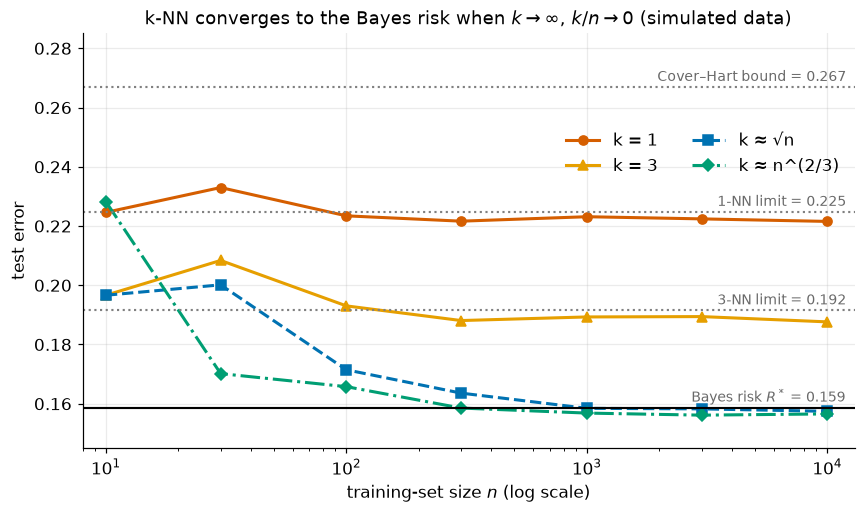

In [20]:
# Figure 4.8 — consistency of k-NN in a simulated world
def figure_4_8():
    fig, ax = plt.subplots(figsize=(8.0, 4.8))
    styles = {"k = 1": (VERMILION, "o", "-"), "k = 3": (ORANGE, "^", "-"), "k ≈ √n": (BLUE, "s", "--"), "k ≈ n^(2/3)": (GREEN, "D", "-.")}
    for name, (color, marker, ls) in styles.items():
        ax.plot(consistency["n"], consistency[name], color=color, marker=marker, linestyle=ls, linewidth=2, label=name)
    for label, value, ls in [("Cover–Hart bound", limits["Cover-Hart bound $2R^*(1-R^*)$"], ":"), ("1-NN limit", limits["1-NN limit"], ":"),
                             ("3-NN limit", limits["3-NN limit"], ":"), ("Bayes risk $R^*$", limits["Bayes risk $R^*$"], "-")]:
        ax.axhline(value, color="black" if ls == "-" else "gray", linestyle=ls, linewidth=1.4)
        ax.text(1.2e4, value + 0.002, f"{label} = {value:.3f}", fontsize=9, color="dimgray", ha="right")
    ax.set_xscale("log")
    ax.set_xlim(8, 1.3e4)
    ax.set(xlabel="training-set size $n$ (log scale)", ylabel="test error", title="k-NN converges to the Bayes risk when $k \\to \\infty$, $k/n \\to 0$ (simulated data)",
           ylim=(0.145, 0.285))
    ax.legend(frameon=False, ncol=2, loc="upper right", bbox_to_anchor=(1.0, 0.80))
    fig.tight_layout()
    plt.show()


figure_4_8()

**Reading the figure.** Three facts stand out. (1) The curves of the two *fixed* values of $k$ stop improving after $n \approx 100$ and settle at their theoretical limits: about 0.222 for $k = 1$ (the limit is 0.225) and 0.189 for $k = 3$ (the limit is 0.192). Having more data does not help a method whose $k$ is stuck: its error is limited by the *variance of a few neighbors*, not by the amount of data. Both limits are above the Bayes risk of 0.159 and below the Cover–Hart bound of 0.267, as Theorem 4.1 says. (2) The two curves with a growing $k$ approach the Bayes risk: at $n = 10{,}000$ they are at 0.157 ($k \approx \sqrt{n} = 101$) and 0.157 ($k \approx n^{2/3} = 465$), indistinguishable from 0.159 within the sampling error of the experiment (about 0.003, because the test set has 20,000 points; that is also why a value slightly below $R^\ast$ is possible). (3) At very small $n$ a large $k$ can *hurt*: for $n = 10$ the rule $k \approx n^{2/3}$ takes $k = 5$ neighbors out of 10 points and is worse than $k = 3$. Consistency is a statement about $n \to \infty$; for each finite $n$ the best $k$ must still be found from the data, which is what Chapter 5 is about.

## 4.7 The curse of dimensionality

Everything so far worked with one or two features, or with Digits, where 64 features turned out to be harmless. The main weakness of local methods appears when the number of features $d$ grows: "close" stops being a useful notion. The phenomenon is called the **curse of dimensionality** (Bellman, 1961), and it has three faces.

### 4.7.1 Three faces of the curse

**1. Neighborhoods are not local.** Suppose the inputs are uniform in the unit cube $[0, 1]^d$, and we want a neighborhood (a sub-cube) that contains a fraction $p$ of the data. Its side must be $p^{1/d}$. For $p = 1\%$ the side is $0.01$ in dimension 1, $0.10$ in dimension 2, $0.63$ in dimension 10 and $0.95$ in dimension 100: **to capture 1% of the data in 100 dimensions we need a cube that spans 95% of the range of every feature.** That is not a neighborhood any more. To have $k$ neighbors in a neighborhood of a given *absolute* side $s$ we need $n \approx k/s^d$ data points: the sample size grows **exponentially** with $d$.

**2. Distances concentrate.** In high dimensions the distance from a point to its nearest neighbor becomes almost as large as the distance to a typical point. If all points are about equally far, the notion of "nearest" loses its meaning (Beyer et al., 1999). The next cell measures it: it draws $n = 1{,}000$ points uniformly in $[0, 1]^d$ (a **simulation**), and compares, for 200 query points, the distance to the nearest point with the average distance to all the points.

**3. Slow rates.** The heuristic argument of Section 4.5.4 for a smooth function in $d$ dimensions says that the $k$ neighbors lie within a radius $r \propto (k/n)^{1/d}$, the bias is of order $r^2 = (k/n)^{2/d}$, so that $\text{bias}^2 + \text{variance} \approx c\,(k/n)^{4/d} + \sigma^2/k$. Minimizing over $k$ gives $k^\ast \propto n^{4/(d+4)}$ and an excess error $\propto n^{-4/(d+4)}$: for $d = 1$ the exponent is $4/5$ of Section 4.5.4, for $d = 10$ it is $4/14 \approx 0.29$. (For merely Lipschitz functions the exponent is $2/(d + 2)$, and this is the *best possible* rate for any method over that class of functions: it is not a weakness of k-NN but of local learning with no other assumption.) Ignoring constants, the number of examples needed to reach the error obtained with $n_0$ examples in dimension 1 is $n_0^{(d+4)/5}$.

In [21]:
rng = np.random.default_rng(SEED)
rows = []
for d in [1, 2, 5, 10, 20, 50, 100, 500, 1000]:
    X_u, Q_u = rng.random((1000, d)), rng.random((200, d))
    D = np.sqrt(np.maximum((Q_u ** 2).sum(1)[:, None] + (X_u ** 2).sum(1)[None, :] - 2 * Q_u @ X_u.T, 0))   # (200, 1000) distances
    rows.append({"d": d, "nearest": D.min(axis=1).mean(), "average": D.mean(axis=1).mean(), "nearest / average": (D.min(axis=1) / D.mean(axis=1)).mean(),
                 "side for 1% of the data": 0.01 ** (1 / d), "side for 10% of the data": 0.1 ** (1 / d)})
concentration = pd.DataFrame(rows).set_index("d")
print(concentration.round(3).to_string())

n0 = 100
need = pd.DataFrame({"exponent 4/(d+4)": [4 / (d + 4) for d in (1, 2, 5, 10, 20)],
                     f"n needed to match n = {n0} at d = 1": [f"{n0 ** ((d + 4) / 5):,.0f}" for d in (1, 2, 5, 10, 20)]}, index=pd.Index([1, 2, 5, 10, 20], name="d"))
print()
print(need.round(2).to_string())

      nearest  average  nearest / average  side for 1% of the data  side for 10% of the data
d                                                                                           
1       0.000    0.335              0.002                    0.010                     0.100
2       0.016    0.525              0.031                    0.100                     0.316
5       0.180    0.871              0.207                    0.398                     0.631
10      0.516    1.278              0.404                    0.631                     0.794
20      1.040    1.809              0.575                    0.794                     0.891
50      2.106    2.877              0.732                    0.912                     0.955
100     3.318    4.070              0.815                    0.955                     0.977
500     8.406    9.139              0.920                    0.991                     0.995
1000   12.169   12.905              0.943                    0.995    

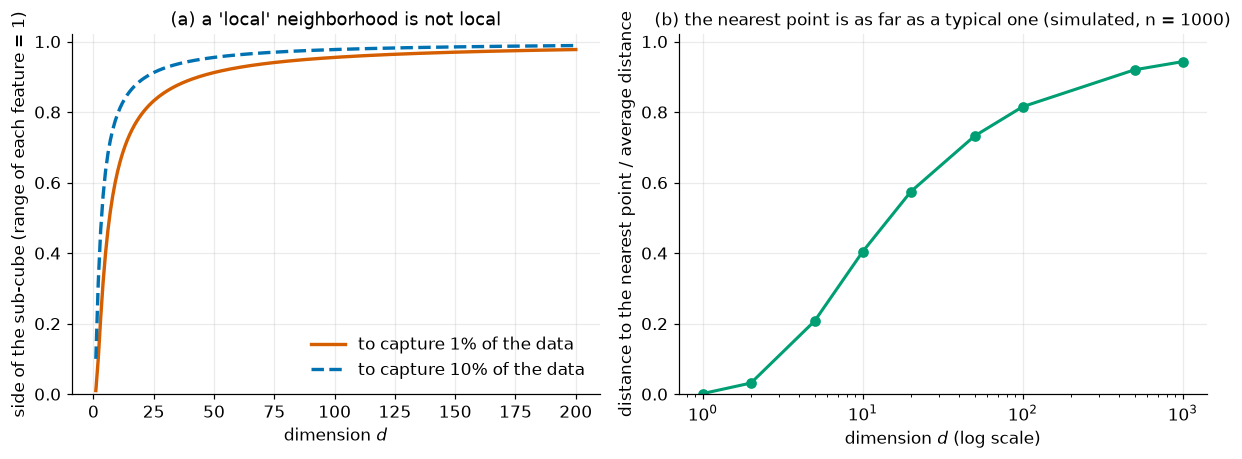

In [22]:
# Figure 4.9 — the geometry of high dimensions
def figure_4_9():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.3))
    d_axis = np.arange(1, 201)
    for p, color, ls in [(0.01, VERMILION, "-"), (0.1, BLUE, "--")]:
        axes[0].plot(d_axis, p ** (1 / d_axis), color=color, linestyle=ls, linewidth=2.2, label=f"to capture {p:.0%} of the data")
    axes[0].set(xlabel="dimension $d$", ylabel="side of the sub-cube (range of each feature = 1)", title="(a) a 'local' neighborhood is not local", ylim=(0, 1.02))
    axes[0].legend(frameon=False, loc="lower right")
    axes[1].plot(concentration.index, concentration["nearest / average"], color=GREEN, marker="o", linewidth=2)
    axes[1].set_xscale("log")
    axes[1].set(xlabel="dimension $d$ (log scale)", ylabel="distance to the nearest point / average distance",
                title="(b) the nearest point is as far as a typical one (simulated, n = 1000)", ylim=(0, 1.02))
    axes[1].title.set_fontsize(11)
    fig.tight_layout()
    plt.show()


figure_4_9()

Panel (a) is the first face: the side of the sub-cube that contains 1% of the data goes from $0.01$ to practically the whole range as $d$ grows, and the one for 10% of the data is already at 0.79 in dimension 10. Panel (b), a simulation, is the second face: the ratio between the distance to the nearest point and the average distance rises from 0.002 in dimension 1 (the nearest of 1,000 points is almost on top of the query) to 0.40 in dimension 10, 0.73 in dimension 50 and 0.94 in dimension 1,000, where **the nearest of the thousand points is only 6% closer than the average one**. The last table is the third face, under the idealized assumptions of the heuristic (the constants are ignored): the exponent of the rate falls from 0.8 in dimension 1 to 0.29 in dimension 10, and the sample size that is needed to match the accuracy obtained with 100 examples in dimension 1 is about 250 in dimension 2, 4,000 in dimension 5, 400,000 in dimension 10 and 4 billion in dimension 20.

### 4.7.2 The curse on real data: irrelevant features

The curse is not only about the number of features, but about the number of *useful* ones. A distance counts every feature equally, so each irrelevant feature adds noise to the distance and moves the points apart without telling the classes apart. We measure it with a real data set, **Breast Cancer** (30 features, standardized inside the pipeline), to which we **append $m$ columns of pure noise** ($\mathcal{N}(0,1)$, independent of the label). We compare 5-NN with logistic regression (a linear model, Chapter 6), which is not based on distances, on 15 random stratified splits.

In [23]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression

X_bc, y_bc = load_breast_cancer(return_X_y=True)
rows = []
for m_noise in [0, 10, 30, 100, 300, 1000]:
    acc_knn, acc_lin = [], []
    for r in range(15):
        noise_cols = np.random.default_rng(r).normal(size=(len(X_bc), m_noise))
        Z = np.hstack([X_bc, noise_cols]) if m_noise else X_bc
        Za, Zb, ya, yb = train_test_split(Z, y_bc, test_size=0.3, random_state=r, stratify=y_bc)
        acc_knn.append(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Za, ya).score(Zb, yb))
        acc_lin.append(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(Za, ya).score(Zb, yb))
    rows.append({"noise features": m_noise, "5-NN": np.mean(acc_knn), "logistic regression": np.mean(acc_lin)})
noise_table = pd.DataFrame(rows)
print(noise_table.round(4).to_string(index=False))

 noise features   5-NN  logistic regression
              0 0.9634               0.9727
             10 0.9505               0.9665
             30 0.9442               0.9622
            100 0.9103               0.9450
            300 0.8823               0.9396
           1000 0.8031               0.9232


The accuracy of 5-NN falls steadily as noise columns are added (from 0.963 to 0.803 with 1,000 of them), while logistic regression loses much less (from 0.973 to 0.923): a model that can learn a weight for each feature can, in principle, give a weight close to zero to a useless one, whereas a distance cannot. Even logistic regression suffers (it has more parameters to estimate from the same 398 training patients, Chapter 3), but k-NN suffers about three times as much. The lesson is practical: **before using a distance-based method, remove the features that you know to be irrelevant**, and consider automatic feature selection (Chapter 10) or a metric learned from the data.

### 4.7.3 Why Digits works: intrinsic dimension

Digits has 64 features, and yet 1-NN reaches 98.5%. Why does the curse not strike? Because the data do not fill the 64-dimensional space: images of digits are strongly constrained (neighboring pixels are correlated, and a handwritten digit has only a handful of "degrees of freedom": slant, thickness, the shape of the loops...), so they lie close to a **low-dimensional surface** inside the space of pixels. What matters for k-NN is this *intrinsic* dimension, not the number of columns. We can check it by projecting the data on their first $m$ **principal components** (Chapter 13 explains how they are obtained; here we only use them as a way of reducing the dimension) and measuring the accuracy of 5-NN on the projection, with the projection fitted on the training set only.

In [24]:
from sklearn.decomposition import PCA

components = [1, 2, 3, 5, 8, 10, 15, 20, 30, 40, 64]
acc_pca = np.zeros((15, len(components)))
for r in range(15):
    Xa, Xb, ya, yb = train_test_split(X_dg, y_dg, test_size=0.3, random_state=r, stratify=y_dg)
    for j, m_comp in enumerate(components):
        model = make_pipeline(PCA(n_components=m_comp, random_state=SEED), KNeighborsClassifier(n_neighbors=5)).fit(Xa, ya)
        acc_pca[r, j] = model.score(Xb, yb)
explained = np.cumsum(PCA().fit(X_dg).explained_variance_ratio_)
pca_table = pd.DataFrame({"components m": components, "5-NN accuracy": acc_pca.mean(axis=0),
                          "variance explained": [explained[m_ - 1] for m_ in components]})
print(pca_table.round(4).to_string(index=False))

 components m  5-NN accuracy  variance explained
            1         0.3341              0.1489
            2         0.6185              0.2851
            3         0.7572              0.4030
            5         0.9181              0.5450
            8         0.9586              0.6739
           10         0.9746              0.7382
           15         0.9802              0.8353
           20         0.9823              0.8943
           30         0.9826              0.9591
           40         0.9833              0.9882
           64         0.9833              1.0000


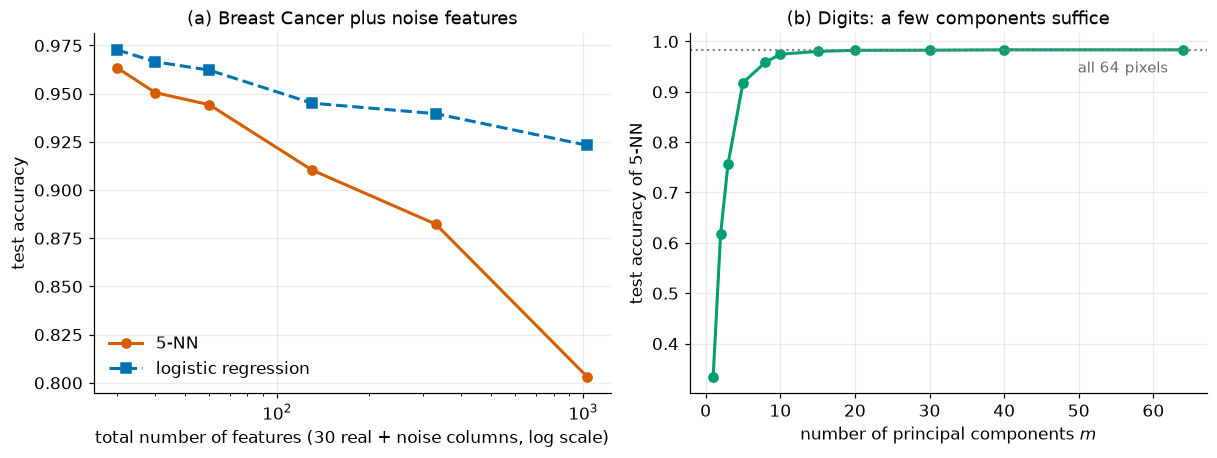

In [25]:
# Figure 4.10 — irrelevant features hurt k-NN; digits live in a low-dimensional subspace
def figure_4_10():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.3))
    ax = axes[0]
    ax.plot(noise_table["noise features"] + 30, noise_table["5-NN"], color=VERMILION, marker="o", linewidth=2, label="5-NN")
    ax.plot(noise_table["noise features"] + 30, noise_table["logistic regression"], color=BLUE, marker="s", linestyle="--", linewidth=2, label="logistic regression")
    ax.set_xscale("log")
    ax.set(xlabel="total number of features (30 real + noise columns, log scale)", ylabel="test accuracy", title="(a) Breast Cancer plus noise features")
    ax.legend(frameon=False, loc="lower left")
    ax = axes[1]
    ax.plot(pca_table["components m"], pca_table["5-NN accuracy"], color=GREEN, marker="o", linewidth=2)
    ax.axhline(acc_pca[:, -1].mean(), color="gray", linestyle=":", linewidth=1.4)
    ax.text(62, acc_pca[:, -1].mean() - 0.045, "all 64 pixels", ha="right", fontsize=9.5, color="dimgray")
    ax.set(xlabel="number of principal components $m$", ylabel="test accuracy of 5-NN", title="(b) Digits: a few components suffice")
    fig.tight_layout()
    plt.show()


figure_4_10()

Panel (a) shows the effect: with 1,000 noise columns, 97% of the features are useless, and 5-NN falls by 16 points while logistic regression falls by 5. Panel (b) shows why Digits is easy for k-NN: the accuracy of 5-NN on the projection on the **first 10 principal components** is already 0.975 (they capture 74% of the variance), with 20 components it reaches 0.982, as good as with all 64 pixels (0.983), and with a single component it is 0.33. The data behave as if they had an *intrinsic dimension* of the order of ten to twenty, which a method that relies on distances can exploit even though the number of columns is 64. **The relevant dimension is the one that the data and the distance actually see, not the number of columns.** This is why dimensionality reduction (Chapter 13) is often the first step before a nearest-neighbor method.

## 4.8 k-NN in practice

### 4.8.1 Choosing the distance and the weights

The Euclidean distance is the default, but nothing forces it. The **Minkowski distance** $\big(\sum_j \lvert x_j - x'_j\rvert^p\big)^{1/p}$ contains the Manhattan distance ($p = 1$), the Euclidean ($p = 2$) and, as $p\to\infty$, the Chebyshev distance $\max_j \lvert x_j - x'_j\rvert$; the **cosine distance** $1 - \frac{\mathbf{x}^\top\mathbf{x}'}{\lVert\mathbf{x}\rVert\,\lVert\mathbf{x}'\rVert}$ compares directions and ignores magnitudes, which is natural for text or for images with variable brightness. The votes can also be **weighted**: with `weights="distance"` each neighbor counts $1/\lVert\mathbf{x} - \mathbf{x}_i\rVert$, so that closer neighbors matter more (and a test point that coincides with a training point takes its label). A weighted k-NN is less sensitive to the exact value of $k$. We compare the options on Digits (raw pixels) and on Wine (all 13 features, standardized), with 20 random stratified splits each.

In [26]:
def compare_variants(X, y, variants, scale=False, n_repeats=20):
    """Mean and standard deviation of the test accuracy, over random stratified 70/30 splits, for each k-NN variant."""
    out = {}
    for name, kwargs in variants.items():
        accs = []
        for r in range(n_repeats):
            Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=r, stratify=y)
            model = KNeighborsClassifier(**kwargs)
            if scale:
                model = make_pipeline(StandardScaler(), model)
            accs.append(model.fit(Xa, ya).score(Xb, yb))
        out[name] = (np.mean(accs), np.std(accs))
    return out


variants = {"Euclidean, uniform votes": dict(n_neighbors=5),
            "Manhattan (p = 1)": dict(n_neighbors=5, p=1),
            "Minkowski p = 3": dict(n_neighbors=5, p=3),
            "Chebyshev (p = infinity)": dict(n_neighbors=5, metric="chebyshev"),
            "cosine": dict(n_neighbors=5, metric="cosine", algorithm="brute"),
            "Euclidean, distance-weighted votes": dict(n_neighbors=5, weights="distance")}
res_digits = compare_variants(X_dg, y_dg, variants)
res_wine = compare_variants(wine.data.to_numpy(), y_w, variants, scale=True)
variant_table = pd.DataFrame({"Digits (mean)": {k: v[0] for k, v in res_digits.items()}, "Digits (std)": {k: v[1] for k, v in res_digits.items()},
                              "Wine (mean)": {k: v[0] for k, v in res_wine.items()}, "Wine (std)": {k: v[1] for k, v in res_wine.items()}})
print(variant_table.round(4).to_string())

                                    Digits (mean)  Digits (std)  Wine (mean)  Wine (std)
Euclidean, uniform votes                   0.9833        0.0040       0.9602      0.0197
Manhattan (p = 1)                          0.9791        0.0045       0.9657      0.0134
Minkowski p = 3                            0.9829        0.0053       0.9509      0.0197
Chebyshev (p = infinity)                   0.9715        0.0076       0.9250      0.0290
cosine                                     0.9816        0.0050       0.9565      0.0213
Euclidean, distance-weighted votes         0.9836        0.0039       0.9630      0.0194


On Digits the Euclidean distance, the cosine distance, the Minkowski distance with $p = 3$ and the distance-weighted vote all give about 0.982 to 0.984, differences that are well inside the standard deviation over splits (0.004 to 0.005); the Manhattan distance is a little lower (0.979) and the Chebyshev distance is clearly the worst (0.972). On Wine the Manhattan distance is the best (0.966, against 0.960 for the Euclidean one), the weighted vote and the cosine distance are close to the Euclidean one, and again the Chebyshev distance is clearly worse (0.925, with a larger variability). The Chebyshev distance looks only at the single feature in which two points differ most, throwing away the information in the others, which is rarely what we want. The practical conclusion is not that one distance is best, but that **the choice among reasonable distances matters much less than the choices of Section 4.7** (which features to include, and how to scale them), and that differences of a few tenths of a point between variants are not evidence of anything unless they are checked with a procedure designed for that (Chapter 5).

### 4.8.2 Scaling, and the choice of $k$

Two rules from earlier chapters apply in full. **Scale the features** (Section 2.7: on the Wine data one feature accounted for 99.8% of the squared distance before standardization), with the scaler fitted on the training set only, inside a pipeline. And **choose $k$ with held-out data, never with the training set** (Figure 4.3: the training accuracy always picks $k = 1$); Chapter 5 shows how, with validation sets and cross-validation. As a starting point, for $n$ examples, $k \approx \sqrt{n}$ is a common rule of thumb (it satisfies the two conditions of Stone's theorem), and for two classes an odd $k$ avoids ties.

### 4.8.3 Speed: brute force against trees

A naive prediction costs $O(nd)$ per query: for $n$ in the millions this is too slow if many queries arrive. **KD-trees** (Bentley, 1975) and **ball trees** organize the training points in a hierarchy of boxes or balls, so that large parts of the data can be discarded without computing a distance, and the search takes about $O(\log n)$ in *low* dimensions. Their efficiency, however, is another face of the curse: as $d$ grows the pruning stops working (all boxes look equally close, Section 4.7.1), and in high dimensions the tree is no better than brute force, and often worse. We measure it on $n = 20{,}000$ standard-Gaussian points and 500 queries, for $k = 5$, with the three algorithms of scikit-learn (the best of three repetitions; the times are in milliseconds and **depend on your machine**).

In [27]:
import time

rng = np.random.default_rng(SEED)
rows = []
for d in [2, 5, 10, 20, 50]:
    X_t, Q_t = rng.normal(size=(20_000, d)), rng.normal(size=(500, d))
    row = {"d": d}
    for algorithm in ["brute", "kd_tree", "ball_tree"]:
        t_build, t_query = [], []
        for _ in range(3):
            t0 = time.perf_counter()
            nn = KNeighborsClassifier(n_neighbors=5, algorithm=algorithm).fit(X_t, np.zeros(len(X_t), dtype=int))
            t1 = time.perf_counter()
            nn.kneighbors(Q_t)
            t_build.append(t1 - t0); t_query.append(time.perf_counter() - t1)
        row[f"{algorithm}: build"] = 1000 * min(t_build)
        row[f"{algorithm}: 500 queries"] = 1000 * min(t_query)
    rows.append(row)
print(pd.DataFrame(rows).set_index("d").round(1).to_string())

    brute: build  brute: 500 queries  kd_tree: build  kd_tree: 500 queries  ball_tree: build  ball_tree: 500 queries
d                                                                                                                   
2            0.5                 5.7             8.4                   1.3               7.3                     7.3
5            0.9                 5.5            10.0                   3.9               6.8                    22.4
10           0.6                 6.1            15.2                  36.3               9.7                    55.3
20           0.9                 6.3            27.2                 167.2              16.6                   110.9
50           1.3                 8.7            64.4                 344.5              35.8                   236.8


In the run printed above, the brute-force query time is almost independent of the dimension (10 to 19 ms for 500 queries: it is one matrix product and a partial sort), and there is no building cost. In dimension 2 the KD-tree answers the queries about ten times faster (1 ms), and the price of building it (5 ms) is repaid after a few hundred queries; in dimension 5 it is still faster than brute force by a factor of about 2.5; at $d = 10$ the trees are already *slower* than brute force, and from $d = 20$ on they are slower by one to two orders of magnitude. The numbers depend on the machine and on the library version, but the pattern is the general one: **trees pay in low dimensions (roughly up to ten features) and not beyond**, brute force is the right baseline otherwise, and scikit-learn's default `algorithm="auto"` chooses among the three with simple rules based on the size and the dimension of the data.

Beyond a few tens of dimensions, exact search is replaced in practice by **approximate** nearest-neighbor methods (hashing, graph-based indexes), which give up the guarantee of returning *exactly* the nearest points in exchange for orders of magnitude of speed; they are the engine of similarity search in large collections of images, documents and embeddings.

## 4.9 Summary

- **The method.** k-NN predicts at $\mathbf{x}$ the average (regression) or the majority vote (classification) of the labels of the $k$ training points closest to $\mathbf{x}$. It has no training phase; the training set is the model. A prediction costs $O(nd)$ with brute force.
- **$k$ is a smoothing parameter.** $k = 1$ interpolates the training data (Voronoi cells, training error 0), large $k$ flattens the fit toward the global mean or majority. The training error always selects $k = 1$ and **cannot be used to choose $k$**; the best $k$ is found with held-out data (Chapter 5) and lies on a plateau that is wider and shifts to larger values when the data are noisier.
- **Bias–variance decomposition.** For the squared loss, $\mathbb{E}[(y_0 - \hat f_S(\mathbf{x}_0))^2] = \sigma^2 + \text{bias}^2 + \text{variance}$: noise that no method can remove, systematic error of the average fit, sensitivity of the fit to the sample. Flexibility lowers the bias and raises the variance; the best model balances the two.
- **k-NN regression in closed form** (fixed design): variance $\sigma^2/k$ (so 1-NN doubles the unavoidable error) and bias equal to $f(\mathbf{x}_0)$ minus the average of $f$ over the neighbors. The best $k$ grows with $n$ ($\propto n^{4/5}$ in the interior for a smooth $f$ in one dimension, $n^{2/3}$ at the boundary), while $k/n$ and the neighborhood width shrink.
- **Consistency.** The 1-NN risk tends to $\mathbb{E}[2\eta(1-\eta)] \le 2R^\ast(1-R^\ast)$ (Cover–Hart), and k-NN is universally consistent when $k \to \infty$ and $k/n \to 0$ (Stone), with no assumption on the distribution; the *rate* depends on the smoothness of the problem and on the dimension.
- **The curse of dimensionality.** In high dimensions neighborhoods are not local (a cube with 1% of the data spans 95% of each range at $d = 100$), distances concentrate (nearest $\approx$ average), and the rate degrades to $n^{-4/(d+4)}$ for smooth functions. What counts is the *intrinsic* dimension and the number of *relevant* features: noise features damage k-NN much more than a linear model (Breast Cancer: 0.963 to 0.803 against 0.973 to 0.923), and Digits works despite its 64 pixels because ten to twenty components carry the information.
- **In practice.** Scale the features (fitted on the training set), remove irrelevant ones, choose $k$ by validation, prefer brute force or a KD-tree according to $d$ (trees pay up to about ten features), and treat the choice of the distance as a secondary matter. On Diabetes, least squares beat k-NN: **a more flexible method wins only if the truth needs the flexibility, or if there is enough data to pay for it.**

### Data sources

- *Digits*: E. Alpaydin and C. Kaynak, "Optical Recognition of Handwritten Digits", UCI Machine Learning Repository (1998). The test portion of the data set, 1,797 images of $8\times8$ pixels, is bundled with scikit-learn.
- *Wine*: M. Forina et al., *PARVUS: An Extendible Package for Data Exploration, Classification and Correlation*, Institute of Pharmaceutical and Food Analysis and Technologies, Genoa (1991). Bundled with scikit-learn.
- *Diabetes*: B. Efron, T. Hastie, I. Johnstone and R. Tibshirani, "Least Angle Regression", *Annals of Statistics* (with discussion), 407–499 (2004). Bundled with scikit-learn; the ten features are centered and scaled by scikit-learn.
- *Breast Cancer Wisconsin (Diagnostic)*: W. N. Street, W. H. Wolberg and O. L. Mangasarian, "Nuclear feature extraction for breast tumor diagnosis", *IS&T/SPIE 1993 International Symposium on Electronic Imaging: Science and Technology*, volume 1905, 861–870 (1993). Bundled with scikit-learn. The 1,000 noise columns of Section 4.7.2 are added by us.
- *Simulated data*: the sine world of Sections 4.5.3 and 4.5.4, the two-Gaussian world of Section 4.6.2, the uniform points of Section 4.7.1 and the points of the timing experiment of Section 4.8.3 are **simulations**, used because the theory needs a distribution or a function that is known exactly.

### Further reading

- E. Fix and J. L. Hodges, "Discriminatory analysis. Nonparametric discrimination: consistency properties", Report 4, USAF School of Aviation Medicine, Randolph Field, Texas (1951). The origin of the nearest-neighbor rule.
- T. M. Cover and P. E. Hart, "Nearest neighbor pattern classification", *IEEE Transactions on Information Theory* 13(1), 21–27 (1967). Theorem 4.1.
- C. J. Stone, "Consistent nonparametric regression", *Annals of Statistics* 5(4), 595–620 (1977). Theorem 4.2.
- L. Devroye, L. Györfi and G. Lugosi, *A Probabilistic Theory of Pattern Recognition*, Springer, 1996. The reference on nearest-neighbor rules, with proofs of consistency and of the slow-rate results.
- L. Györfi, M. Kohler, A. Krzyżak and H. Walk, *A Distribution-Free Theory of Nonparametric Regression*, Springer, 2002. Rates of convergence of k-NN and kernel regression.
- T. Hastie, R. Tibshirani and J. Friedman, *The Elements of Statistical Learning*, 2nd ed., Springer, 2009. Chapter 2 (local methods and the curse of dimensionality), Chapter 7 (bias–variance) and Chapter 13 (nearest-neighbor methods).
- S. Geman, E. Bienenstock and R. Doursat, "Neural networks and the bias/variance dilemma", *Neural Computation* 4(1), 1–58 (1992).
- R. E. Bellman, *Adaptive Control Processes: A Guided Tour*, Princeton University Press, 1961. Where the "curse of dimensionality" was named.
- K. Beyer, J. Goldstein, R. Ramakrishnan and U. Shaft, "When is 'nearest neighbor' meaningful?", *International Conference on Database Theory (ICDT)*, 217–235 (1999).
- J. L. Bentley, "Multidimensional binary search trees used for associative searching", *Communications of the ACM* 18(9), 509–517 (1975). The KD-tree.
- K. Q. Weinberger and L. K. Saul, "Distance metric learning for large margin nearest neighbor classification", *Journal of Machine Learning Research* 10, 207–244 (2009). Learning the metric from the data.

## 4.10 Exercises

Difficulty: ★ warm-up, ★★ core, ★★★ challenge. Try each exercise before reading the hint; solutions and detailed outlines are in [Appendix C](../appendices/appendix_c_solutions.ipynb).

### Manual (analytical) exercises

**Exercise 4.1 ★ — k-NN by hand, with weights.** One-dimensional training set: $x = 1, 2, 4, 7, 9, 10$ with labels $0, 0, 1, 1, 0, 0$. (a) Classify the query $x = 5$ with $k = 1, 3, 5$ and the Euclidean distance. (b) Classify it again with $k = 5$ and **distance-weighted** votes (each neighbor counts $1/\lvert x - x_i\rvert$). (c) What happens with $k = 6$ and uniform votes? Is the answer a property of the data or of the method? (d) What is the training error of 1-NN on this set? And of 6-NN?

*Hint.* List the six distances first and sort them; mind the tie at distance 4.

**Exercise 4.2 ★ — Bias and variance at the boundary and in the interior.** The training inputs are $x_i = (i - 1)/100$, $i = 1, \dots, 101$ (so $x \in [0, 1]$ with step $0.01$), the true function is $f(x) = x$, and the noise has variance $\sigma^2 = 0.25$. (a) Using the formulas of Section 4.5.2, compute the bias, the variance and the expected squared error of k-NN regression at the **boundary** point $x_0 = 0$, as a function of $k$. (b) Do the same at the **central** point $x_0 = 0.5$ for odd $k$. (c) Find the best $k$ at each of the two points. What does the difference tell you about using a single $k$ for the whole input range?

*Hint.* At $x_0 = 0$ the $k$ nearest neighbors are $x_1, \dots, x_k$, with average $(k - 1)/200$. At $x_0 = 0.5$ the neighbors are symmetric and the average of the linear function equals $f(x_0)$.

**Exercise 4.3 ★★ — Cover–Hart with numbers.** A binary problem has $\eta(\mathbf{x}) = \mathbb{P}(y = 1 \mid \mathbf{x})$ equal to $0.9$ on one half of the input space (in probability) and to $0.2$ on the other half. (a) Compute the Bayes risk $R^\ast$. (b) Compute the limit of the 1-NN risk and compare it with $2R^\ast(1 - R^\ast)$. (c) Compute the limit of the 3-NN risk. (d) How much of the gap between 1-NN and Bayes is closed by $k = 3$?

*Hint.* For three neighbors with $\eta$ fixed, the vote is for class 1 with probability $p_1 = 3\eta^2 - 2\eta^3$; the rule errs with probability $\eta(1 - p_1) + (1 - \eta)\,p_1$. Average over the two halves.

**Exercise 4.4 ★★ — Counting in high dimensions.** Inputs are uniform in $[0, 1]^d$. (a) How many training points must a sample contain so that the *expected* number of points in a cube of side $0.1$ is 1, for $d = 1, 2, 5, 10, 20$? (b) With $n = 10^6$ points, what side must the cube have to contain on average $k = 10$ points, for $d = 2, 10, 50, 100$? (c) What fraction of the points of the unit cube lies within $0.05$ of the boundary (closer than $0.05$ to at least one face), as a function of $d$? Evaluate it for $d = 2, 10, 50$.

*Hint.* The expected number of points in a cube of side $s$ is $n s^d$. For (c) compute the probability of the complement: all coordinates in $[0.05, 0.95]$.

**Exercise 4.5 ★★★ — The best $k$ in $d$ dimensions.** Suppose that the inputs have a uniform density on a set of volume 1 in $\mathbb{R}^d$, that $f$ is $L$-Lipschitz, $\lvert f(\mathbf{x}) - f(\mathbf{x}')\rvert \le L\lVert\mathbf{x} - \mathbf{x}'\rVert$, and that the noise has variance $\sigma^2$. (a) The $k$ nearest neighbors of a point lie, approximately, in a ball of radius $r$ with $k = n\,v_d\,r^d$, where $v_d$ is the volume of the unit ball. Show that the expected excess error of k-NN regression is at most $L^2 r^2 + \sigma^2/k$. (b) Minimize over $k$ and show that $k^\ast = \big(\tfrac{d\sigma^2}{2L^2}\big)^{d/(d+2)}(n v_d)^{2/(d+2)}$ and that the minimal bound is proportional to $n^{-2/(d+2)}$. (c) By what factor must $n$ grow to **halve** the error bound in $d = 1, 2, 5, 10$? (d) Evaluate $k^\ast$ for $n = 10^4$, $L = \sigma = 1$ and $d = 1, 5, 10$ (use $v_1 = 2$, $v_5 = 5.264$, $v_{10} = 2.550$) and comment.

*Hint.* For (a) the bias at $\mathbf{x}_0$ is the average of $f(\mathbf{x}_0) - f(\mathbf{x}_i)$ over neighbors at distance at most $r$, so $\lvert\text{bias}\rvert \le Lr$. For (b) set the derivative of $L^2(k/(nv_d))^{2/d} + \sigma^2/k$ with respect to $k$ to zero.

### Python (computational) exercises

**Exercise 4.6 ★ — k-NN regression from scratch.** Write `knn_regress(X_train, y_train, X_test, k)` that returns the average of the targets of the $k$ nearest neighbors, using the Gram-matrix distances of Worked example 2.1 and `np.argpartition`. Compare it with `KNeighborsRegressor` on the 10 features of the Diabetes data, with 30 random 70/30 splits and $k = 20$: how often do the two sets of predictions coincide, and what is the mean test MSE?

*Hint.* Reuse the structure of `knn_predict` of Section 4.2.2; the prediction is `y_train[nearest].mean(axis=1)`.

**Exercise 4.7 ★★ — Bias and variance by simulation, with a random design.** Let $f(x) = \mathbb{I}[x > 0.5]$ (a step), $\sigma = 0.3$, and let the training inputs be **random**, $x_i \sim \mathcal{U}[0, 1]$, $n = 100$. Generate 2,000 training sets. (a) For k-NN regression with $k = 1, 5, 10, 20, 50$ estimate, at $x_0 = 0.2$ and at $x_0 = 0.5$ (at the jump), the bias$^2$, the variance and the expected test error. (b) Do the same for polynomial regression of degree $1, 3, 9$ (`np.polyfit`). (c) Comment on where the bias comes from in each method and on which method is better at which point.

*Hint.* For each training set compute the prediction at the two points; the bias$^2$ is (mean prediction $- f(x_0))^2$, the variance is the variance of the prediction over the 2,000 sets, and the expected test error is $\sigma^2$ + bias$^2$ + variance.

**Exercise 4.8 ★★ — Kernel regression: fixed bandwidth against fixed $k$.** The Nadaraya–Watson estimator replaces the "$k$ nearest" by a smooth weighting with a **bandwidth** $h$: $\hat f_h(x) = \sum_i K\big((x - x_i)/h\big)\,y_i\big/\sum_i K\big((x - x_i)/h\big)$, with the Gaussian kernel $K(u) = e^{-u^2/2}$. (a) Implement it for the Diabetes data with the single feature `bmi`. (b) Find the best $h$ on a grid with 20 random 70/30 splits and compare the test MSE with the best k-NN of Section 4.4 (about 3,966 for $k = 40$). (c) Plot the two fits on the whole data set. In which regions of the input do they differ most, and why? (Hint for (c): think about how many data points lie in a window of fixed width where the data are sparse.)

*Hint.* Guard against a division by zero far from every point (a very small $h$ makes all weights underflow): for instance subtract the smallest squared distance before exponentiating.

**Exercise 4.9 ★★★ — Rescuing k-NN from irrelevant features.** On Breast Cancer, append $m = 100$ and then $m = 1000$ columns of Gaussian noise as in Section 4.7.2. (a) Compare, on 15 splits, the test accuracy of 5-NN (standardized), of 5-NN preceded by `SelectKBest(f_classif, k=30)` **inside the pipeline**, and of logistic regression. (b) How many of the original 30 features are among the 30 selected, on average? (c) Repeat (a) with the selection done **before** the split, on the whole data set (the leak of Section 2.7), and comment on what you see.

*Hint.* `make_pipeline(StandardScaler(), SelectKBest(f_classif, k=30), KNeighborsClassifier(n_neighbors=5))`; the selected columns are given by `pipe[1].get_support()`; the original features are the first 30 columns.

**Exercise 4.10 ★★★ — Consistency and the curse together.** The world is: two equally likely classes, $\mathbf{x} \mid y \sim \mathcal{N}(\boldsymbol\mu_y, \mathbf{I}_d)$, with $\boldsymbol\mu_0 = \mathbf{0}$ and $\boldsymbol\mu_1 = (2, 0, \dots, 0)^\top$: only the first coordinate carries information, so the Bayes risk is $\Phi(-1) = 0.1587$ in every dimension $d$. (a) For $d = 2$ and $d = 10$, train k-NN with $k \approx \sqrt{n}$ and with $k \approx n^{2/3}$ (odd), for $n = 30, 100, 300, 1000, 3000, 10000$, and estimate the test error on 20,000 fresh points (6 repetitions). (b) Plot the errors against $n$ with the Bayes risk. (c) For each $d$ find the smallest $n$ in the grid for which the error is within 0.01 of the Bayes risk, and relate the result to Section 4.7.

*Hint.* Reuse the structure of the experiment of Section 4.6.2; draw `X = rng.normal(size=(n, d)); X[:, 0] += 2 * y`.

## What comes next

We have studied one method in depth, and the main lesson is general: **every learning method has a knob that trades bias for variance, and the knob must be set with data it has not seen.** **Chapter 5** is devoted to that: validation sets, cross-validation, nested cross-validation, tuning hyperparameters systematically, and the metrics (precision, recall, ROC curves) that tell whether a classifier is good *for the purpose at hand*. **Chapter 6** introduces the opposite assumption to k-NN: a *global* parametric model, the linear one, together with its regularization (ridge, regularized logistic regression), which is another knob of the same kind, whose bias and variance we shall analyze with the tools of this chapter. The kernel smoother of Exercise 4.8 anticipates the kernels of **Chapter 9**; the irrelevant features of Section 4.7.2 return in the feature selection and the sparse models of **Chapter 10**; decision trees (**Chapter 11**) are also local averages, but with neighborhoods that *adapt* to the data and ignore irrelevant features; and the intrinsic dimension of Section 4.7.3 will be made precise by PCA in **Chapter 13**.